# 1. Introduction
## What drives success for teams in the FIFA world cup and what factors influence match outcomes?
Objectives:
- Explore historical World Cup performance
- Investigate factors associated with tournament success
- Examine player and team characteristics
- Identify trends and correlations

Notes

Areas to investigate:

- success score = max stage * count?
- no of wins / appearances in finals as a % for overall for each team over all matches not just finals
- in any of their games against any teams, win or lose, calc goal diff and get average so who scores most goals relative to their opponent
- higher goal difference shows aggression: + or - so - means youre conceding more than you score.
- average player age? age range/median/etc - correlate age to athleticism
- no of caps correlate to wins, average caps in team per WC , outside and and inside the world cup. find datasets external - all matches they played ever, combine and groupby player, another column to see if in world cups
- maybe see assists in other data
- all data before the WC ie between tournaments, no of unique players, government funding

Top 3 of all time in terms of winning FIFA tournament:
1. Brazil
2. Italy
3. Argentina

## 2. Data Loading & Initial Exploration


### Import packages

In [1516]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors
import seaborn as sns
from datetime import datetime
import re
from pathlib import Path
import datetime 
from scipy import stats
from scipy.optimize import curve_fit
import pprint as pp

### Load Raw Data

In [1517]:
# Contains 49,393 International football results from 1872 to 2026. The matches range from FIFA World Cup to FIFI Wild Cup to regular friendly matches. 
# Used for analysing historical WC success
fp1 = Path.cwd().parent/'data'/'International_football_results_1872_to_2026'/'results.csv'
df = pd.read_csv(fp1)

# Contains 183 matches. Full match-level data including teams, scores, stage, venue, city, country, date, and match notes.
# Used for analysing team performance metrics
fp2 = Path.cwd().parent/'data'/'world_cup_complete_dataset'/'wc_all_matches.csv'
df2 = pd.read_csv(fp2)

# Contains 48 qualified teams. Group assignment, confederation, FIFA rank, head coach, best-ever World Cup result, and 2026 debut indicator.
# Used for analysing team performance metrics
fp3 = Path.cwd().parent/"data"/"world_cup_complete_dataset"/"wc_2026_teams.csv"
teams_df = pd.read_csv(fp3)

# Contains data on ~ 17,000 FIFA football players including but not limited to player names, nationalities, clubs, player ratings, potential, positions, ages, and various skill attributes.
# Used for analysing player performance metrics
fp4 = Path.cwd().parent/"data"/"players_data.csv"
players_df = pd.read_csv(fp4)

# Contains player performance attributes e.g assists, yellow cards, minutes played etc.
# Used for analysing player performance metrics 
fp5 = Path.cwd().parent/"data"/"player_performances.csv"
perform_df = pd.read_csv(fp5)

# Contains information about each player such as their height, citizenship, date of birth etc.
# Used for analysing player performance metrics
fp6 = Path.cwd().parent/"data"/"player_profiles.csv"
profiles_df = pd.read_csv(fp6)

# Contains player ID and their market values, linked to player_profiles 
fp7 = Path.cwd().parent/"data"/"player_market_value.csv"
mv_df = pd.read_csv(fp7)

# Contains team competition seasons data
fp8 = Path.cwd().parent/"data"/"team_competitions_seasons.csv"
comps_df = pd.read_csv(fp8)

C:\Users\bevamin\AppData\Local\Temp\ipykernel_27296\404020736.py:29: DtypeWarning: Columns (0: third_club_url, 1: third_club_name, 2: fourth_club_url, 3: fourth_club_name) have mixed types. Specify dtype option on import or set low_memory=False.
  profiles_df = pd.read_csv(fp6)


### Initial Exploration

In [1518]:
df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False


In [1519]:
print(df.describe())
print(df.info())

         home_score    away_score
count  49501.000000  49501.000000
mean       1.757197      1.181936
std        1.773821      1.401655
min        0.000000      0.000000
25%        1.000000      0.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max       31.000000     21.000000
<class 'pandas.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        49505 non-null  str    
 1   home_team   49505 non-null  str    
 2   away_team   49505 non-null  str    
 3   home_score  49501 non-null  float64
 4   away_score  49501 non-null  float64
 5   tournament  49505 non-null  str    
 6   city        49505 non-null  str    
 7   country     49505 non-null  str    
 8   neutral     49505 non-null  bool   
dtypes: bool(1), float64(2), str(6)
memory usage: 3.1 MB
None


In [1520]:
df2.head(184)

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN
...,...,...,...,...,...,...,...,...,...,...,...
179,2022,Quarter-final,France,2,1,England,Al Bayt Stadium,Al Khor,Qatar,2022-12-10,Kane pen miss
180,2022,Semi-final,Argentina,3,0,Croatia,Lusail Stadium,Lusail,Qatar,2022-12-13,Messi pen + Álvarez 2
181,2022,Semi-final,France,2,0,Morocco,Al Bayt Stadium,Al Khor,Qatar,2022-12-14,NaN
182,2022,3rd Place,Croatia,2,1,Morocco,Khalifa International,Al Rayyan,Qatar,2022-12-17,NaN


In [1521]:
print(df2.describe())
print(df2.info())

              year      score1      score2
count   184.000000  184.000000  184.000000
mean   1984.260870    2.358696    1.152174
std      27.962844    1.746700    1.436714
min    1930.000000    0.000000    0.000000
25%    1962.000000    1.000000    0.000000
50%    1990.000000    2.000000    1.000000
75%    2010.000000    3.000000    2.000000
max    2022.000000    9.000000   10.000000
<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   year     184 non-null    int64
 1   stage    184 non-null    str  
 2   team1    184 non-null    str  
 3   score1   184 non-null    int64
 4   score2   184 non-null    int64
 5   team2    184 non-null    str  
 6   venue    184 non-null    str  
 7   city     184 non-null    str  
 8   country  184 non-null    str  
 9   date     184 non-null    str  
 10  notes    102 non-null    str  
dtypes: int64(3), str(8)
memory usage: 15.9 KB
None

In [1522]:
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No


In [1523]:
print(teams_df.describe())
print(teams_df.info())

       fifa_rank
count  48.000000
mean   34.062500
std    24.577629
min     1.000000
25%    13.750000
50%    29.500000
75%    52.250000
max    95.000000
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   team            48 non-null     str  
 1   group           48 non-null     str  
 2   confederation   48 non-null     str  
 3   fifa_rank       48 non-null     int64
 4   coach           48 non-null     str  
 5   best_wc_result  48 non-null     str  
 6   debut_2026      48 non-null     str  
dtypes: int64(1), str(6)
memory usage: 2.8 KB
None


In [1524]:
players_df.head()

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,6/24/1987,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,2/14/1992,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,3/15/1993,25,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,6/4/1991,27,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,6/20/1991,27,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [1525]:
print(players_df.describe())
print(players_df.info())

                age     height_cm    weight_kgs  overall_rating     potential  \
count  17954.000000  17954.000000  17954.000000    17954.000000  17954.000000   
mean      25.565445    174.946921     75.301047       66.240169     71.430935   
std        4.705708     14.029449      7.083684        6.963730      6.131339   
min       17.000000    152.400000     49.900000       47.000000     48.000000   
25%       22.000000    154.940000     69.900000       62.000000     67.000000   
50%       25.000000    175.260000     74.800000       66.000000     71.000000   
75%       29.000000    185.420000     79.800000       71.000000     75.000000   
max       46.000000    205.740000    110.200000       94.000000     95.000000   

         value_euro      wage_euro  international_reputation(1-5)  \
count  1.769900e+04   17708.000000                   17954.000000   
mean   2.479280e+06    9902.134628                       1.111674   
std    5.687014e+06   21995.593750                       0.3921

In [1526]:
perform_df.head()

,player_id,season_name,competition_id,competition_name,team_id,team_name,nb_in_group,nb_on_pitch,goals,assists,own_goals,subed_in,subed_out,yellow_cards,second_yellow_cards,direct_red_cards,penalty_goals,minutes_played,goals_conceded,clean_sheets
0,1,08/09,OBLG,NOFV-Oberliga Süd,4825,FC Eilenburg,9,9,0.0,0,0,0,2,0,0,1,0,NaN,0,0
1,1,07/08,RS,Regionalliga Süd,1526,FSV Ludwigshafen Oggersheim,22,22,1.0,0,0,3,8,1,0,0,0,1580.0,0,0
2,1,06/07,L2,2. Bundesliga,996,TuS Koblenz,10,4,0.0,0,0,4,0,0,0,0,0,NaN,0,0
3,1,06/07,DFB,DFB-Pokal,996,TuS Koblenz,1,0,0.0,0,0,0,0,0,0,0,0,NaN,0,0
4,1,05/06,L2,2. Bundesliga,66,SpVgg Unterhaching,26,14,1.0,1,0,12,1,1,0,0,0,388.0,0,0


In [1527]:
print(perform_df.describe())
print(perform_df.info())

          player_id       team_id   nb_in_group   nb_on_pitch         goals  \
count  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06  1.740517e+06   
mean   2.916295e+05  1.069298e+04  9.929085e+00  8.156783e+00  9.527192e-01   
std    2.922079e+05  1.770314e+04  1.084346e+01  9.865284e+00  2.283932e+00   
min    1.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00  0.000000e+00   
25%    5.549400e+04  7.980000e+02  2.000000e+00  1.000000e+00  0.000000e+00   
50%    1.894820e+05  3.060000e+03  4.000000e+00  3.000000e+00  0.000000e+00   
75%    4.477680e+05  1.144900e+04  1.600000e+01  1.300000e+01  1.000000e+00   
max    1.453181e+06  1.345500e+05  5.100000e+01  5.100000e+01  5.000000e+01   

            assists     own_goals      subed_in     subed_out  yellow_cards  \
count  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06   
mean   4.469455e-01  1.532853e-02  1.673163e+00  1.855993e+00  1.111522e+00   
std    1.247370e+00  1.300537e-01  3.035122e+00  3.

In [1528]:
profiles_df.head()

,player_id,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,height,citizenship,...,on_loan_from_club_id,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death
0,1,silvio-adzic,Silvio Adzic (1),https://img.a.transfermarkt.technology/portrai...,NaN,1980-09-23,Grünstadt,Germany,0.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100011,everton-silva,Éverton Silva (100011),https://img.a.transfermarkt.technology/portrai...,Éverton José Modesto da Silva,1988-08-04,São João de Meriti,Brazil,171.0,Brazil,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,miroslav-klose,Miroslav Klose (10),https://img.a.transfermarkt.technology/portrai...,Miroslav Josef Klose,1978-06-09,Opole,Germany,184.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,john-thompson,John Thompson (10001),https://img.a.transfermarkt.technology/portrai...,John Paul Thompson,1981-10-12,Dublin,Ireland,183.0,Ireland,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100001,carlos-auzqui,Carlos Auzqui (100001),https://img.a.transfermarkt.technology/portrai...,Carlos Daniel Auzqui,1991-03-16,Longchamps,Argentina,180.0,Argentina,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1529]:
print(profiles_df.describe())
print(profiles_df.info())

          player_id        height  current_club_id  player_agent_id  \
count  9.267100e+04  92667.000000     92671.000000     38057.000000   
mean   4.822020e+05    144.619908     17268.764835      5654.314160   
std    3.894922e+05     73.368611     28780.506345      4038.521566   
min    1.000000e+00      0.000000         1.000000         1.000000   
25%    1.214005e+05    171.000000       123.000000      2325.000000   
50%    4.021140e+05    180.000000      1533.000000      4906.000000   
75%    7.989040e+05    185.000000     22177.000000      8598.000000   
max    1.459023e+06    210.000000    134553.000000     15015.000000   

       on_loan_from_club_id  
count           3758.000000  
mean           14245.704364  
std            23763.128575  
min                2.000000  
25%              738.000000  
50%             3901.000000  
75%            14926.000000  
max           132806.000000  
<class 'pandas.DataFrame'>
RangeIndex: 92671 entries, 0 to 92670
Data columns (total 34 co

In [1530]:
mv_df.head()

,player_id,date_unix,value
0,1000135,2023-12-19,100000.0
1,1000135,2024-06-23,100000.0
2,10,2005-01-06,9000000.0
3,10,2008-06-03,20000000.0
4,10,2009-08-29,12000000.0


In [1531]:
comps_df.head()

,club_division,club_id,competition_id,competition_name,season_draws,season_goal_difference,season_goals_against,season_goals_for,season_id,season_is_two_point_system,...,season_manager_manager_name,season_manager_manager_slug,season_points,season_points_against,season_points_for,season_rank,season_season,season_total_matches,season_wins,team_name
0,Third Tier,1,L3,3. Liga,4,5,16,21,2025,False,...,Alois Schwartz,alois-schwartz,19.0,NaN,NaN,3,25/26,11,5,1.FC Saarbrücken
1,Third Tier,1,L3,3. Liga,11,12,47,59,2024,False,...,Alois Schwartz,alois-schwartz,65.0,NaN,NaN,3,24/25,38,18,1.FC Saarbrücken
2,Third Tier,1,L3,3. Liga,15,17,43,60,2023,False,...,Rüdiger Ziehl,rudiger-ziehl,60.0,NaN,NaN,5,23/24,38,15,1.FC Saarbrücken
3,Third Tier,1,L3,3. Liga,9,25,39,64,2022,False,...,Rüdiger Ziehl,rudiger-ziehl,69.0,NaN,NaN,5,22/23,38,20,1.FC Saarbrücken
4,Third Tier,1,L3,3. Liga,11,6,44,50,2021,False,...,Uwe Koschinat,uwe-koschinat,53.0,NaN,NaN,7,21/22,36,14,1.FC Saarbrücken


## 3. Data Cleaning

In [1532]:
'''Added match_winner column'''

df2['match_winner'] = df2.apply(lambda x: x['team1'] if x['score1'] > x['score2'] else (x['team2'] if x['score2'] > x['score1'] else 'Draw'), axis=1)
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match,France
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN,USA
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN,Yugoslavia
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN,Uruguay
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN,Argentina


In [1533]:
'''filtered df to show only finals matches'''

finals_df = df2[(df2['stage'] == 'Final')]

'''some match winners results are Draw, so need to check notes to see who actually won, eg if it went to penalties'''

finals_with_notes = finals_df[finals_df['match_winner'] == 'Draw'] 
finals_with_notes.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Draw
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Draw
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Draw


In [1534]:
'''based on above, need to change match winner column for those specific matches to reflect actual winner.'''

df2.loc[106, 'match_winner'] = 'Brazil'
df2.loc[135, 'match_winner'] = 'Italy'
df2.loc[183, 'match_winner'] = 'Argentina'

'''check that results were changed'''

df2.loc[[106, 135, 183]]

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Brazil
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Italy
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Argentina


In [1535]:
def text_only(x):
    '''Removes dates from the values to just get the stage name'''
    return re.sub(r'\s*\(.*\)', '', x)

unique_results = teams_df['best_wc_result'].apply(text_only).unique()
unique_results

<StringArray>
[  'Quarter-finals',      'Group stage',      'Semi-finals',
        'Runner-up',          'Winners',      'Third place',
      'Round of 16', 'First appearance']
Length: 8, dtype: str

In [1536]:
''' add age column to profiles_df'''
profiles_df['date_of_birth'] = pd.to_datetime(profiles_df['date_of_birth'])
today = pd.Timestamp.today()
profiles_df['age'] = (today.year - profiles_df['date_of_birth'].dt.year)

In [1537]:
'''Create new cleaned best_wc_result column'''
teams_df['best_stage_clean'] = teams_df['best_wc_result'].map(text_only)
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,best_stage_clean
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,Quarter-finals
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,Group stage
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,Semi-finals
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,Runner-up
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,Group stage


In [1538]:
'''change birth_date column from str to date (US - MM-DD-YYYY)'''

players_df['birth_date'] = pd.to_datetime(players_df['birth_date'])

'''get today's date'''
today = pd.Timestamp.today()
print(today)

'''change age column to reflect current actual age'''
players_df['age'] = (today.year - players_df['birth_date'].dt.year)
players_df.head()

2026-11-01 11:20:15.350379


,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,39,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,34,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,1993-03-15,33,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,1991-06-04,35,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,1991-06-20,35,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [1539]:
''' Change this date column from str to date'''
mv_df['date_unix'] = pd.to_datetime(mv_df['date_unix'])
mv_df['date_unix'].dtype

dtype('<M8[us]')

## 4. Match Outcomes

### Neutral Venue Analysis

True ie higher score for home team:  18451
False ie NOT a higher score for home team:  17909
Neutral game count:  13145
all rows count=  49505
percent home wins: 37.27%
percent away wins: 36.18%
percent neutral: 26.55%


Text(0.5, 1.0, 'Percentage splits of match scores depending on location')

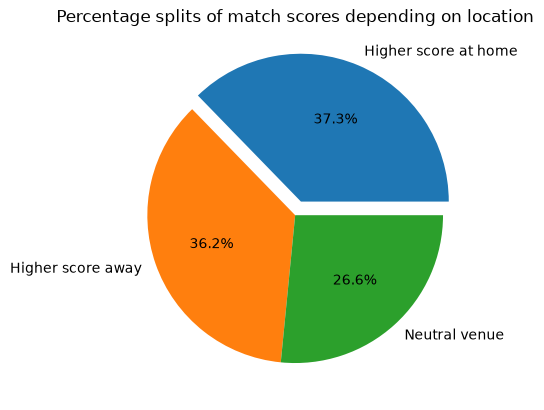

In [1540]:
'''Does playing at a neutral venue affect score?'''   

# new column to show if home score was greater than away score
df['higher_score_for_home'] = np.where(((df['home_score'] > df['away_score']) & (df['neutral'] == False)), True, False)

true_count = df['higher_score_for_home'].sum() # counts Trues only
false_count = (~df['higher_score_for_home']).sum()
neutral_count = len(df[df['neutral'] == True])
false_count -= neutral_count
all_rows = true_count + false_count + neutral_count

percent_home_higher_score = (true_count / all_rows) * 100
percent_away_higher_score = (false_count / all_rows) * 100
percent_neutral = (neutral_count / all_rows) * 100

print(f'True ie higher score for home team: ', true_count)
print(f'False ie NOT a higher score for home team: ', false_count)
print(f'Neutral game count: ', neutral_count)
print(f'all rows count= ', true_count + false_count + neutral_count)
print(f"percent home wins: {round(percent_home_higher_score, 2)}%\npercent away wins: {round(percent_away_higher_score,2)}%\npercent neutral: {round(percent_neutral,2)}%")

# plot pie chart
values = [percent_home_higher_score, percent_away_higher_score, percent_neutral]
labels = ['Higher score at home', 'Higher score away', "Neutral venue"]
explode = (0.1, 0, 0)
plt.pie(values, labels=labels, autopct='%1.1f%%', explode=explode)
plt.title('Percentage splits of match scores depending on location')

Observation:  
Neutral venues (i.e. where the match location was in neither team's country) had little impact on match outcome, however, there was a slight bias toward teams scoring higher when they played at home vs a neutral venue.

## 5. Historical World Cup Success

<Axes: title={'center': 'Top 10 Home Teams with Most Goals'}, xlabel='Team', ylabel='Total Home Goals'>

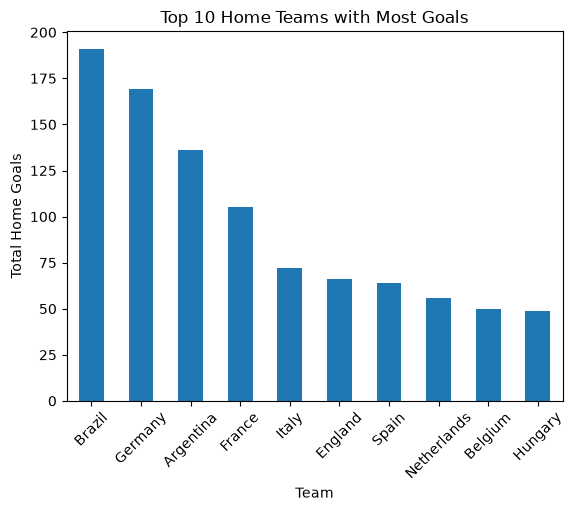

In [1541]:
'''Team with most goals when they played at home'''

df[df['tournament'] == 'FIFA World Cup'].groupby('home_team')['home_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Home Teams with Most Goals', rot=45, ylabel = 'Total Home Goals', xlabel="Team")

Observation:  
Teams that scored the most goals over time across all World Cups were Brazil, followed by Germany, Argentina and France. The remaining teams in the top 10 had similar totals.


<Axes: title={'center': 'Top 10 Away Teams with Most Goals'}, xlabel='Team', ylabel='Total Away Goals'>

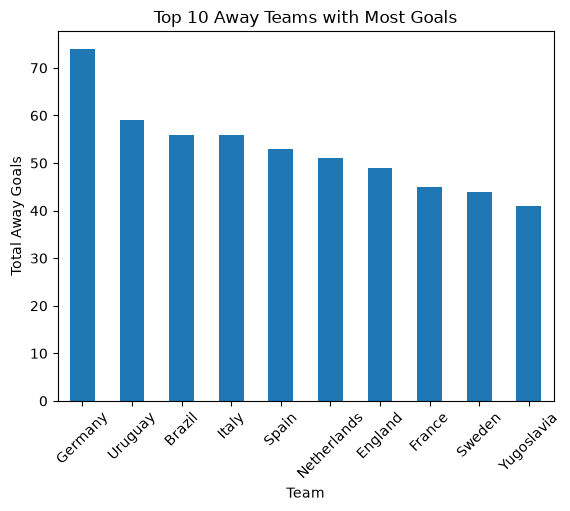

In [1542]:
'''Team with most goals when they played away'''

df[df['tournament'] == 'FIFA World Cup'].groupby('away_team')['away_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Away Teams with Most Goals', rot=45, ylabel = 'Total Away Goals',  xlabel="Team")

Observation:  
Interestingly, when they played as the away team, Brazil was not the top scoring team. Instead, Germany have scored the most over time when they played away.

home_team
Brazil         79.0
Germany        70.0
Argentina      52.0
Italy          45.0
France         44.0
England        36.0
Spain          35.0
Netherlands    32.0
Uruguay        25.0
Belgium        24.0
dtype: float64


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Brazil'),
  Text(1, 0, 'Germany'),
  Text(2, 0, 'Argentina'),
  Text(3, 0, 'Italy'),
  Text(4, 0, 'France'),
  Text(5, 0, 'England'),
  Text(6, 0, 'Spain'),
  Text(7, 0, 'Netherlands'),
  Text(8, 0, 'Uruguay'),
  Text(9, 0, 'Belgium')])

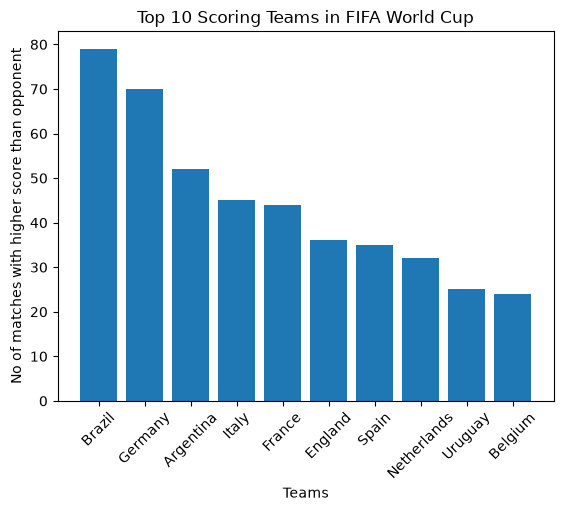

In [1543]:
'''highest scoring team overall'''

# remove the rows where tournament is not FIFA World Cup
fifa_only_df = df[df['tournament'] == 'FIFA World Cup']

# team that won the most over time, so need to calculate total wins by doing their home score - away score depending on where they played
top_scoring_team = fifa_only_df.copy()
top_scoring_team['home_win'] = top_scoring_team['home_score'] > top_scoring_team['away_score']
top_scoring_team['away_win'] = top_scoring_team['away_score'] > top_scoring_team['home_score']

top_scoring_team_overall = top_scoring_team.groupby('home_team')['home_win'].sum() + top_scoring_team.groupby('away_team')['away_win'].sum()
print(top_scoring_team_overall.sort_values(ascending=False).head(10))

top_scorers_list = top_scoring_team_overall.sort_values(ascending=False).head(10)
labels = top_scorers_list.index
counts = top_scorers_list.values
plt.bar(labels, counts)
plt.title('Top 10 Scoring Teams in FIFA World Cup')
plt.ylabel('No of matches with higher score than opponent')
plt.xlabel('Teams')
plt.xticks(rotation=45)



Observation:  
Combining home and away goals for each team shows that the teams in previous results i.e.- Brazil, Germany, Argentina etc, have had more matches where they scored more goals against their opponent vs other teams by a clear margin, even within the top 10 (e.g. Brazil = 79 vs Belgium = 24)

### Success by Era

8
<class 'numpy.ndarray'>
[Timestamp('1942-12-31 00:00:00'), Timestamp('1954-12-31 00:00:00'), Timestamp('1966-12-31 00:00:00'), Timestamp('1978-12-31 00:00:00'), Timestamp('1990-12-31 00:00:00'), Timestamp('2002-12-31 00:00:00'), Timestamp('2014-12-31 00:00:00'), Timestamp('2026-07-11 00:00:00')]


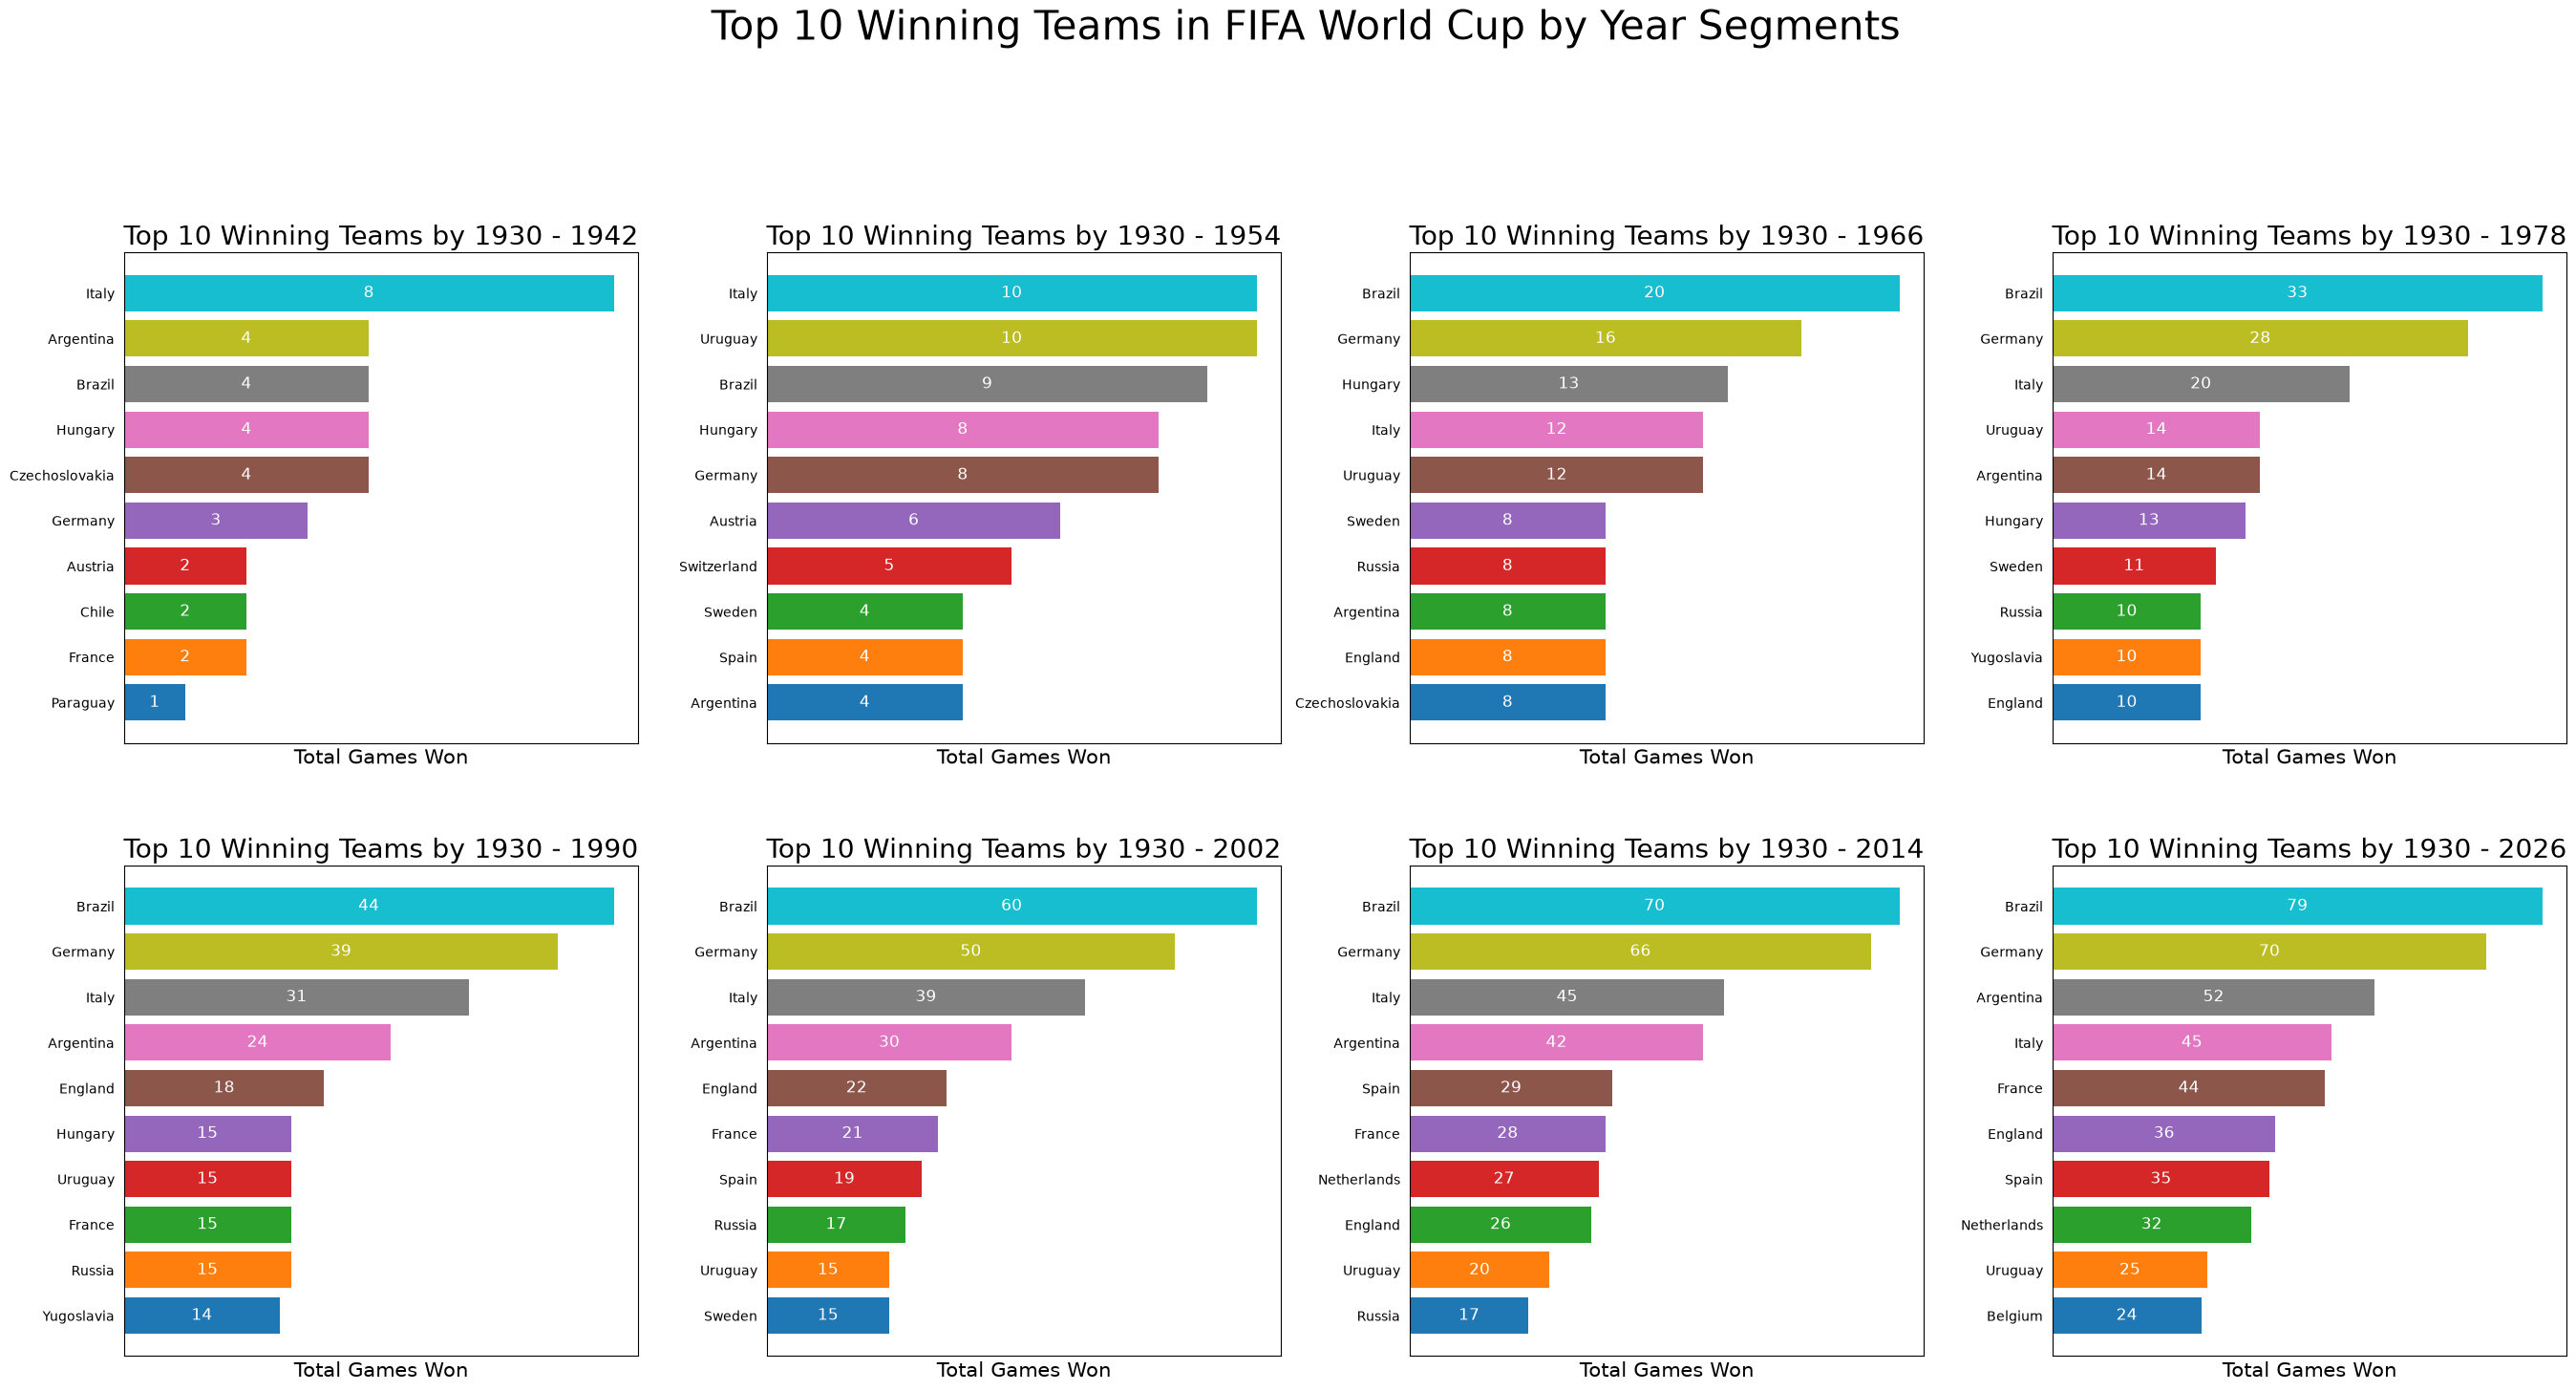

In [1544]:
# SPLIT BY EVERY 20 YRS

# date from str to date
top_scoring_team['date'] = pd.to_datetime(top_scoring_team['date'], format='%Y-%m-%d')

earliest_date = top_scoring_team.date.min()
latest_date = top_scoring_team.date.max()

no_of_segments = (latest_date.year - earliest_date.year) // 12
print(no_of_segments)

fig, ax = plt.subplots(2, 4, figsize = (33, 15))
print(type(ax))

timepoints = [date for date in pd.date_range(start=earliest_date, end=latest_date, freq='12YE')]
timepoints.pop(0)
timepoints.append(latest_date)
print(timepoints)

flattened_ax = ax.flatten()

for n, date in enumerate(timepoints):
    filtered_df = top_scoring_team[top_scoring_team['date'] < date]
    current_ax = flattened_ax[n]
    winning_team_overall = filtered_df.groupby('home_team')['home_win'].sum() + filtered_df.groupby('away_team')['away_win'].sum()
    winners_list = winning_team_overall.sort_values(ascending=False).head(10)
    winners_list.sort_values(ascending=True, inplace=True)
    p = current_ax.barh(winners_list.index, winners_list.values, color = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan'])
    fig.suptitle('Top 10 Winning Teams in FIFA World Cup by Year Segments', fontsize=30, y=1.05)
    current_ax.set_title(f'Top 10 Winning Teams by {earliest_date.year} - {date.year}', fontsize=20)
    current_ax.set_yticks(range(10))
    current_ax.set_xlabel('Total Games Won', fontsize=15)
    current_ax.tick_params(axis='y', left=False)
    current_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    current_ax.bar_label(p, label_type='center', fmt='%d', fontsize=12, color='white')
fig.subplots_adjust(hspace=0.25, wspace=0.25)



- Italy were the clear lead in terms of World cup match wins from 1930-1942, with Uruguay, Brazil, Hungary and Germany catching up after 1942.  
- Note World War II (no World Cups were held in 1942 and 1946).  
- Brazil continued to dominate post WW2 until the present (2026), closely followed by Germany throughout the decades. 

In [1545]:
'''Filtered df to show only World Cup matches'''
world_cups_df = df[df['tournament'] == "FIFA World Cup"]
world_cups_df = world_cups_df.reset_index(drop=True)

'''Add a year column'''
world_cups_df['year'] = world_cups_df["date"].str.split("-").apply(lambda x: x[0])

'''Add new columns to aid analysis'''
world_cups_df['match_winner'] = world_cups_df.apply(lambda x: x['home_team'] if x['home_score'] > x['away_score'] else (x['away_team'] if x['away_score'] > x['home_score'] else 'Draw'), axis=1)
world_cups_df['goal_diff_for_winner'] = world_cups_df.apply(lambda x: x['home_score'] - x['away_score'] if x['match_winner'] == x['home_team'] else (x['away_score'] - x['home_score'] if x['match_winner'] != x['home_team'] else 0), axis=1)
world_cups_df['goal_diff_for_loser'] = world_cups_df['goal_diff_for_winner'] * -1
world_cups_df['home_goal_diff'] = np.where(world_cups_df['home_team'] == world_cups_df['match_winner'], world_cups_df['goal_diff_for_winner'], world_cups_df['goal_diff_for_loser'])
world_cups_df['away_goal_diff'] = np.where(world_cups_df['away_team'] == world_cups_df['match_winner'], world_cups_df['goal_diff_for_winner'], world_cups_df['goal_diff_for_loser'])

'''Find unique WC years'''
wc_years_unique = world_cups_df['year'].unique()

'''Create a df for each WC year'''
dfs_by_years = []
for year in wc_years_unique:
    dfs_by_years.append(world_cups_df[world_cups_df['year'] == year])

print(len(dfs_by_years))
dfs_by_years[0].head()

23


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,higher_score_for_home,year,match_winner,goal_diff_for_winner,goal_diff_for_loser,home_goal_diff,away_goal_diff
0,1930-07-13,Belgium,United States,0.0,3.0,FIFA World Cup,Montevideo,Uruguay,True,False,1930,United States,3.0,-3.0,-3.0,3.0
1,1930-07-13,France,Mexico,4.0,1.0,FIFA World Cup,Montevideo,Uruguay,True,False,1930,France,3.0,-3.0,3.0,-3.0
2,1930-07-14,Brazil,Yugoslavia,1.0,2.0,FIFA World Cup,Montevideo,Uruguay,True,False,1930,Yugoslavia,1.0,-1.0,-1.0,1.0
3,1930-07-14,Peru,Romania,1.0,3.0,FIFA World Cup,Montevideo,Uruguay,True,False,1930,Romania,2.0,-2.0,-2.0,2.0
4,1930-07-15,Argentina,France,1.0,0.0,FIFA World Cup,Montevideo,Uruguay,True,False,1930,Argentina,1.0,-1.0,1.0,-1.0


In [1546]:
'''Concat the 2 filtered parts of the df'''
all_matches = pd.concat([world_cups_df[['year', 'home_team', 'home_goal_diff']].rename(columns={'home_team': 'team', 'home_goal_diff': 'goal_diff'}), world_cups_df[['year', 'away_team', 'away_goal_diff']].rename(columns={'away_team': 'team','away_goal_diff': 'goal_diff'})])

'''calculate the mean goal diff per team'''
mean_goal_diff_all_time = (all_matches.groupby('team')['goal_diff'].mean().reset_index(name='mean_goal_diff all time').sort_values('mean_goal_diff all time', ascending=False)).reset_index(drop=True)
top_teams = mean_goal_diff_all_time.head(10).copy()

top_teams

,team,mean_goal_diff all time
0,Brazil,1.134454
1,Hungary,0.937500
2,Germany,0.931034
3,Netherlands,0.847458
4,France,0.807692
5,Argentina,0.645161
6,Portugal,0.625000
7,Italy,0.614458
8,Spain,0.583333
9,England,0.531646


In [1547]:
'''Finals wins ie WC tournament wins'''
finals_matches_dates = []
for df in dfs_by_years:
    finals_matches_dates.append(df['date'].max())

'''remove 2026 date from this list as the df is incomplete for 2026'''
finals_matches_dates.remove('2026-07-11')

finals_matches_df = world_cups_df[world_cups_df['date'].isin(finals_matches_dates)]

'''1938 and 1950 had 2 finals matches on same day so has 2 rows - only the final should be captured'''
finals_matches_df = finals_matches_df.drop([51, 74], axis=0)

'''Some finals matches match_winner = Draw, when there was a winner due to penalties.
   Find these rows and change the result to reflect actual winner'''
draws = finals_matches_df[finals_matches_df['match_winner'] == 'Draw']

# Change 1994 Brazil vs Italy final = Draw --> Brazil who won 3-2 on penalties
finals_matches_df.loc[515, 'match_winner'] = 'Brazil'
# Change 2006 Italy vs France final = Draw --> Italy who won 5-3 on penalties
finals_matches_df.loc[707, 'match_winner'] = 'Italy'
# Change 2022 Argentina vs France final = Draw --> Argentina who won 4-2 on penalties
finals_matches_df.loc[963, 'match_winner'] = 'Argentina'


finals_winners = finals_matches_df.groupby('match_winner').agg(years=('year', list), count=('year', 'count')).sort_values(by='count', ascending=False)
finals_winners

,years,count
match_winner,,
Brazil,"[1958, 1962, 1970, 1994, 2002]",5
Germany,"[1954, 1974, 1990, 2014]",4
Italy,"[1934, 1938, 1982, 2006]",4
Argentina,"[1978, 1986, 2022]",3
Uruguay,"[1930, 1950]",2
France,"[1998, 2018]",2
England,[1966],1
Spain,[2010],1


<Axes: title={'center': 'World Cup Winners'}, xlabel='Team', ylabel='No of Wins'>

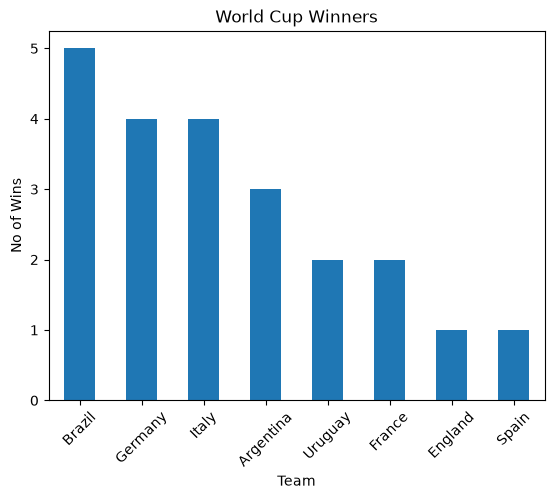

In [1548]:
finals_winners.plot(kind='bar', title='World Cup Winners', rot=45, ylabel = 'No of Wins',  xlabel="Team", legend=False)

In [1549]:
''' mean goal diff per team per WC year - pivot table'''
mean_goal_diff_by_year = all_matches.pivot_table(index='team',columns='year',values='goal_diff',aggfunc='mean')
mean_goal_diff_by_year.head()

year,1930,1934,1938,1950,1954,1958,1962,1966,1970,1974,...,1990,1994,1998,2002,2006,2010,2014,2018,2022,2026
team,,,,,,,,,,,,,,,,,,,,,
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.666667,0.000000,NaN,NaN,-1.00
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.333333,NaN,NaN,NaN,NaN,NaN
Argentina,1.8,-1.0,NaN,NaN,NaN,-1.666667,-0.333333,0.5,NaN,-0.500000,...,0.142857,0.5,1.200000,0.0,1.600000,0.800000,0.571429,-0.75,1.0,1.80
Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.666667,...,NaN,NaN,NaN,NaN,-0.250000,-1.000000,-2.000000,-1.00,-0.5,0.00
Austria,NaN,0.0,NaN,NaN,1.0,-1.666667,NaN,NaN,NaN,NaN,...,-0.333333,NaN,-0.333333,NaN,NaN,NaN,NaN,NaN,NaN,-0.75


In [1550]:
'''Concat the 2 filtered parts of the df'''
matches = pd.concat([world_cups_df[['year', 'home_team', 'match_winner']].rename(columns={'home_team': 'team'}), world_cups_df[['year', 'away_team', 'match_winner']].rename(columns={'away_team': 'team'})])

'''calculate the no of match wins per year per team THEN DO PIVOT TABLE'''
no_match_wins = matches.groupby('team').agg(match_wins=('team', 'count')).sort_values(by='match_wins', ascending=False)
most_matches_won = no_match_wins.head(10).copy()

most_matches_won

,match_wins
team,
Brazil,119
Germany,116
Argentina,94
Italy,83
England,80
France,79
Spain,73
Mexico,65
Uruguay,62


In [1551]:
''' no match wins per team per WC year - STUCK''' 
# match_wins_by_year = most_matches_won.pivot_table(index='team',columns='year',values='match_wins')
# match_wins_by_year.head()

' no match wins per team per WC year - STUCK'

Argentina
Brazil
England
France
Germany
Hungary
Italy
Netherlands
Portugal
Spain
['Brazil', 'Hungary', 'Germany', 'Netherlands', 'France', 'Argentina', 'Portugal', 'Italy', 'Spain', 'England']


Text(0.5, 1.0, 'Mean Goal Difference 1930-2026')

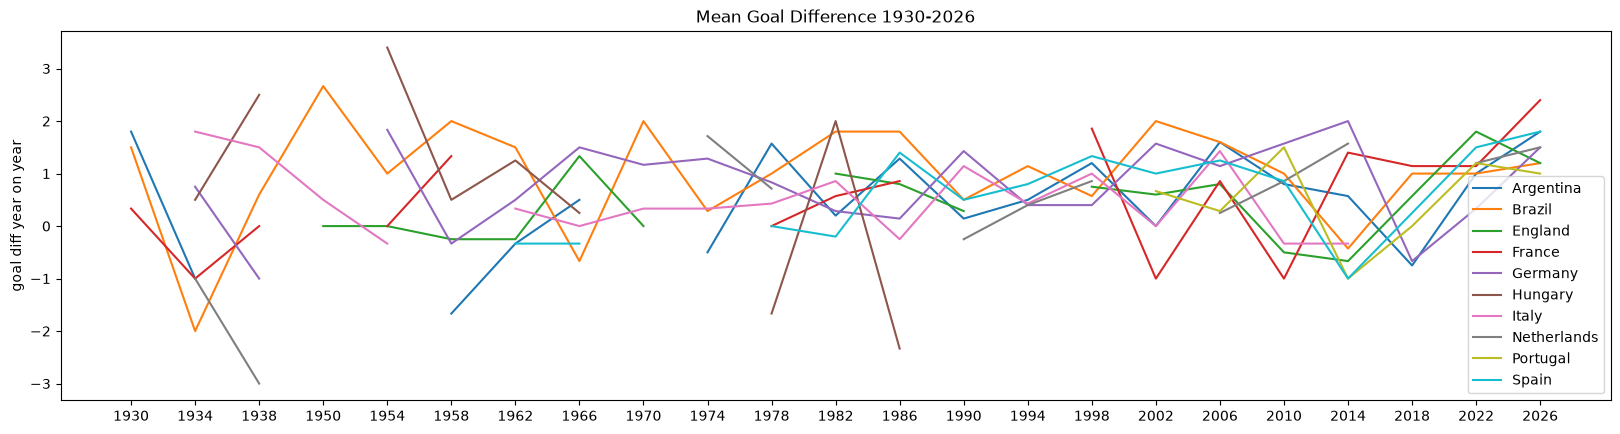

In [1552]:
'''Visualisation to show mean goal diff changes over time for the top 5 teams in terms of goal diff'''

teams_labels = mean_goal_diff_by_year.index.get_level_values('team').values
years_labels = mean_goal_diff_by_year.columns

team_top_list = top_teams['team'].to_list()
for team, data in mean_goal_diff_by_year.iterrows():
    if team in team_top_list:
        print(team)
        plt.plot(years_labels, data, label = team)

print(team_top_list)
plt.legend()
plt.gcf().set_figwidth(20)
plt.ylabel("goal diff year on year")
plt.title("Mean Goal Difference 1930-2026")

-0.2


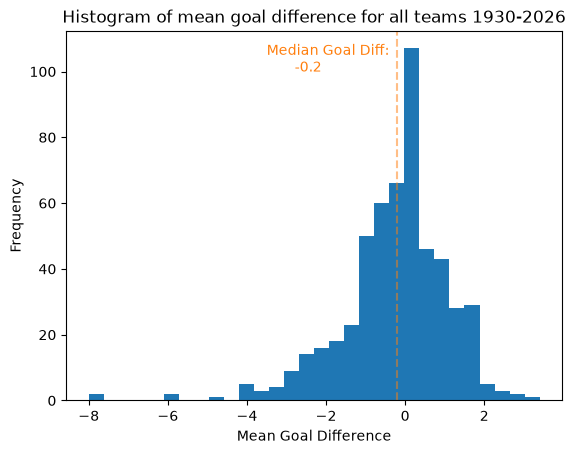

In [1553]:
''' Histogram of mean goal difference for all teams 1930-2026 '''

values = mean_goal_diff_by_year.to_numpy()
values = values.flatten()
mask = np.logical_not(np.isnan(values))
values = values[mask]

print(np.median(values))
plt.hist(values, bins = 30)
plt.title("Histogram of mean goal difference for all teams 1930-2026")
plt.axvline(np.median(values), ls="--", color = "tab:orange", alpha=0.5)
plt.text(-3.5, 100, "Median Goal Diff:\n       -0.2", color="tab:orange")
plt.ylabel("Frequency")
plt.xlabel('Mean Goal Difference')
plt.show()


## 6. Team Performance Metrics

In [1554]:
'''new columns - goal difference''' #IGNORE

df2['goal_diff_winner'] = df2.apply(lambda x: (x['score1'] - x['score2'] if x['team1'] == x['match_winner'] else (x['score2'] - x['score1'] if x['team2'] == x['match_winner'] else 0)),axis=1)
df2['goal_diff_loser'] = df2.apply(lambda x: (x['score1'] - x['score2'] if x['team1'] != x['match_winner'] else (x['score2'] - x['score1'] if x['team2'] != x['match_winner'] else 0)),axis=1)

In [1555]:
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner,goal_diff_winner,goal_diff_loser
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match,France,3,-3
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN,USA,3,-3
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN,Yugoslavia,1,-1
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN,Uruguay,1,-1
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN,Argentina,3,-3


In [1556]:
''' Calculate average goal difference per team - uses df2 IGNORE''' 

def find_team_data(team_name: str):
    '''returns a copy of df2 for each team when they play as 'team1' and 'team2' '''
    team1_df = df2[df2['team1'] == team_name]
    team2_df = df2[df2['team2'] == team_name]
    team_df = pd.concat([team1_df, team2_df])
    return team_df.copy()


# getting unique team names as a list called 'teams'
teams = df2['team1'].to_list()
other_teams = df2['team2'].to_list()
teams.extend(other_teams)
teams = list(set(teams))
teams.sort()


def get_game_counts(team_name: str):
    '''returns the number of matches each team have ever played'''
    game_count = len(df2[(df2['team1'] == team_name) | (df2['team1'] == team_name)])
    return game_count

# initialise dictionaries to store our results
team_dfs = {}
game_counts = {}

for team in teams:
    current_df = find_team_data(team)
    team_dfs[team] = current_df
    current_game_count = get_game_counts(team) 
    game_counts[team] = current_game_count


# 'data' is a dataframe for each team. Add new column to get goal difference depending on whether the team won or lost
for team, data, in team_dfs.items():
    data[f"{team} goal diff"] = data.apply(lambda x: x['goal_diff_winner'] if team == x['match_winner'] else x['goal_diff_loser'], axis=1)


# dictionary to store teams' average goal differences
avg_goal_diff = {}
for team, data, in team_dfs.items():
    average = data[f"{team} goal diff"].mean()
    avg_goal_diff[team] = average


game_count_df = pd.Series(game_counts, name='game_count_df')
goal_diff_df = pd.Series(avg_goal_diff, name='goal_diff_df')
merged_df = pd.merge(goal_diff_df, game_count_df, left_index=True, right_index=True).reset_index()
merged_df.columns = ["Team", "mean goal difference", 'no of matches']
merged_df['total goal difference'] = merged_df["mean goal difference"] * merged_df["no of matches"]
merged_df = merged_df.sort_values(by='total goal difference', ascending=False)

merged_df.head()

#median_no_games = merged_df['no of matches'].median()

# only include teams in the average goal diff metric if they are in top 75% of games played count?


,Team,mean goal difference,no of matches,total goal difference
6,Brazil,0.875000,31,27.125000
19,Germany,1.272727,14,17.818182
23,Italy,0.800000,18,14.400000
18,France,0.960000,15,14.400000
21,Hungary,2.285714,3,6.857143


### Best Stage Reached

In [1557]:
'''Map the stages to a numeric score and add this as a new column'''

stage_map = {
'First appearance': 0,
'Group stage': 1,
'Round of 16': 2,
'Quarter-finals': 3,
'Semi-finals': 4,
'Third place': 5,
'Runner-up': 6,
'Winners': 7
}

teams_df['best_stage_score'] = teams_df['best_stage_clean'].map(stage_map)
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,best_stage_clean,best_stage_score
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,Quarter-finals,3
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,Group stage,1
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,Semi-finals,4
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,Runner-up,6
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,Group stage,1


In [1558]:
'''Get the years that each team got their best result (from best_wc_result column) and correlate that year with avg goal diff for that year per team using df'''

unique_teams = teams_df['team'].unique
top_teams = finals_winners.index

def get_years(string):
    '''takes best_wc_result year values into a list'''
    match = re.search(r"\((.*?)\)", str(string))
    if match:
        return match.group(1).split(',')
    return []

teams_df['years'] = teams_df['best_wc_result'].apply(get_years)
teams_df_filt = teams_df.drop(columns=['group', 'confederation', 'fifa_rank', 'coach', 'debut_2026'], axis='columns')
teams_df_filt


,team,best_wc_result,best_stage_clean,best_stage_score,years
0,Mexico,"Quarter-finals (1970,1986)",Quarter-finals,3,"[1970, 1986]"
1,South Africa,"Group stage (1998,2002,2010)",Group stage,1,"[1998, 2002, 2010]"
2,South Korea,Semi-finals (2002),Semi-finals,4,[2002]
3,Czechia,"Runner-up (1934,1962)",Runner-up,6,"[1934, 1962]"
4,Canada,"Group stage (1986,2022)",Group stage,1,"[1986, 2022]"
5,Switzerland,"Quarter-finals (1934,1938,1954)",Quarter-finals,3,"[1934, 1938, 1954]"
6,Qatar,Group stage (2022),Group stage,1,[2022]
7,Bosnia and Herzegovina,Group stage (2014),Group stage,1,[2014]
8,Brazil,"Winners (1958,1962,1970,1994,2002)",Winners,7,"[1958, 1962, 1970, 1994, 2002]"
9,Morocco,Semi-finals (2022),Semi-finals,4,[2022]


In [1559]:
fifa_df = df[df['tournament'] == 'FIFA World Cup'].sample(5)
fifa_df

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,higher_score_for_home,year,match_winner,goal_diff_for_winner,goal_diff_for_loser,home_goal_diff,away_goal_diff
1043,2026-07-01,England,DR Congo,2.0,1.0,FIFA World Cup,Atlanta,United States,True,False,2026,England,1.0,-1.0,1.0,-1.0
1051,2026-07-03,Colombia,Ghana,1.0,0.0,FIFA World Cup,Kansas City,United States,True,False,2026,Colombia,1.0,-1.0,1.0,-1.0
1049,2026-07-03,Australia,Egypt,1.0,1.0,FIFA World Cup,Arlington,United States,True,False,2026,Draw,0.0,-0.0,-0.0,-0.0
1063,2026-07-11,Argentina,Switzerland,NaN,NaN,FIFA World Cup,Kansas City,United States,True,False,2026,Draw,NaN,NaN,NaN,NaN
1061,2026-07-10,Spain,Belgium,NaN,NaN,FIFA World Cup,Inglewood,United States,True,False,2026,Draw,NaN,NaN,NaN,NaN


In [1560]:
# dict for each team for each year in the list or 1 dict per team with values as list? - STUCK

avg_gd_per_team_per_yr = {}
for team in top_teams:
    if str(team) in str(teams_df_filt['team']):
         years_list = teams_df_filt['years']
         for year in years_list:
              print(year)
    #              if str(team) == str(fifa_df['match_winner']):
    #                    print(team)
    #                    if year == fifa_df['date'][0:4]:
    #                         avg_goal_diff = fifa_df['goal_diff_for_winner'].mean()      
    # avg_gd_per_team_per_yr[team] = avg_goal_diff
                        
#avg_gd_per_team_per_yr


['1970', '1986']
['1998', '2002', '2010']
['2002']
['1934', '1962']
['1986', '2022']
['1934', '1938', '1954']
['2022']
['2014']
['1958', '1962', '1970', '1994', '2002']
['2022']
['1974']
['multiple']
['1930']
['2010']
['2006', '2022']
['2002']
['1954', '1974', '1990', '2014']
[]
['2006', '2010', '2014']
['2006']
['1974', '1978', '2010']
['2002', '2010', '2018', '2022']
['1958']
['6 apps']
['2018']
['1934']
['6 apps']
['1982', '2010']
['2010']
[]
['1994']
['1930', '1950']
['1998', '2018']
['2002']
['1994', '1998']
['1986']
['1978', '1986', '2022']
['2014']
['1954']
[]
['1966', '2006']
['1974']
[]
['2014']
['1966']
['2018']
['2010']
['2018']
['1970', '1986']
['1998', '2002', '2010']
['2002']
['1934', '1962']
['1986', '2022']
['1934', '1938', '1954']
['2022']
['2014']
['1958', '1962', '1970', '1994', '2002']
['2022']
['1974']
['multiple']
['1930']
['2010']
['2006', '2022']
['2002']
['1954', '1974', '1990', '2014']
[]
['2006', '2010', '2014']
['2006']
['1974', '1978', '2010']
['2002', '201

,best_stage_score,avg_goal_diff
best_stage_score,1.000000,0.244341
avg_goal_diff,0.244341,1.000000


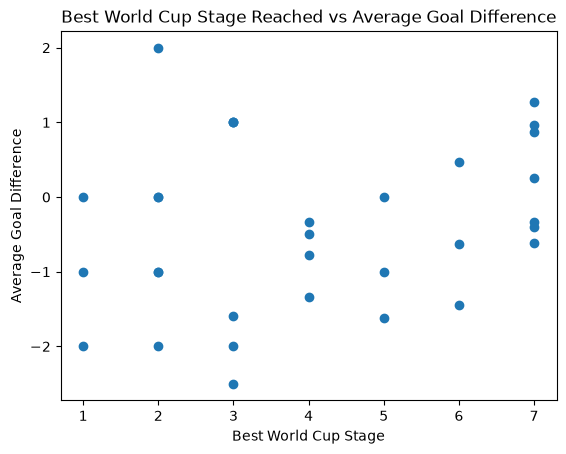

In [1561]:
'''Correlate best_stage_score with other factors e.g avg goals scored per game/avg goal diff/ possession etc''' # teams_df is 2026 only, except for best_wc_result col

filtered_corr_df = teams_df[['team', 'best_stage_score']]

# Corrected this as it was previously 'Turkiye' causing a NaN 
filtered_corr_df.loc[15, 'team'] = 'Turkey'

'''Best world cup stage vs average goal difference'''

def map_goal_diff(team):
    '''iterate through the avg_goal_diff dict and return the goal_diff'''
    for teamname, goal_diff in avg_goal_diff.items():
        if team == teamname:
            return goal_diff
    return None          

filtered_corr_df['avg_goal_diff'] = filtered_corr_df['team'].map(map_goal_diff)

fig, ax = plt.subplots()
ax.scatter(filtered_corr_df['best_stage_score'], filtered_corr_df['avg_goal_diff'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goal Difference')
ax.set_title('Best World Cup Stage Reached vs Average Goal Difference')

corr_coeff = filtered_corr_df[['best_stage_score', 'avg_goal_diff']].corr()
corr_coeff

,best_stage_score,avg_goals_scored_per_game
best_stage_score,1.000000,-0.088339
avg_goals_scored_per_game,-0.088339,1.000000


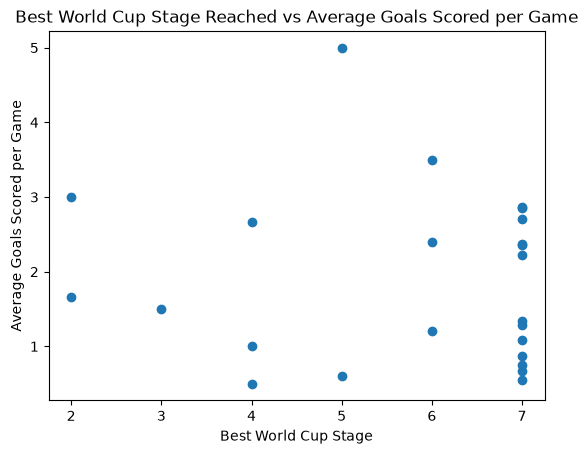

In [1562]:
'''Best World Cup Stage Reached vs avg number of goals scored per game'''

avg_goals_game_t1 = df2.groupby('team1').agg(avg_goals_scored_per_game=('score1', 'mean')).sort_values(by='avg_goals_scored_per_game', ascending=False)
avg_goals_game_t2 = df2.groupby('team2').agg(avg_goals_scored_per_game=('score2', 'mean')).sort_values(by='avg_goals_scored_per_game', ascending=False)
combined_avg_goals_game = pd.concat([avg_goals_game_t1, avg_goals_game_t2])
combined_avg_goals_game.drop_duplicates(inplace=True)

avg_goals_vs_filtered_corr_df = pd.merge(combined_avg_goals_game, filtered_corr_df, how='left', left_index=True, right_on='team')
avg_goals_vs_filtered_corr_df.head(10)

fig, ax = plt.subplots()
ax.scatter(avg_goals_vs_filtered_corr_df['best_stage_score'], avg_goals_vs_filtered_corr_df['avg_goals_scored_per_game'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goals Scored per Game')
ax.set_title('Best World Cup Stage Reached vs Average Goals Scored per Game')

corr_coeff = avg_goals_vs_filtered_corr_df[['best_stage_score', 'avg_goals_scored_per_game']].corr()
corr_coeff


# for a specific world cup event in a singular year
# calculate all participating teams goal diff, either average or sum to aggregate
# for each team, plot their stage reached as x and the average goal diff as y

,best_stage_score,avg_goals_conceded_per_game
best_stage_score,1.000000,-0.323852
avg_goals_conceded_per_game,-0.323852,1.000000


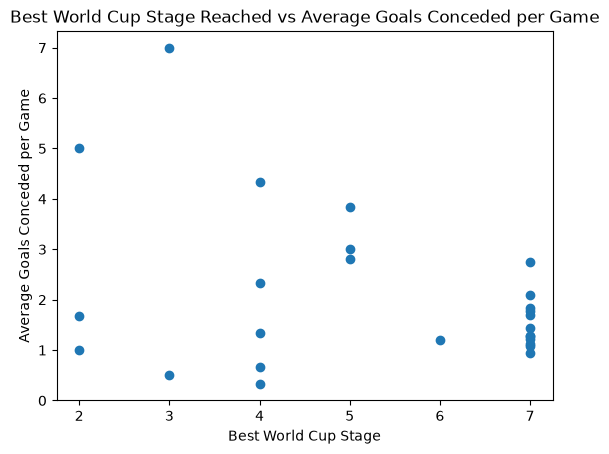

In [1563]:
'''goals conceded vs stage reached'''

avg_concede_game_t1 = df2.groupby('team1').agg(avg_goals_conceded_per_game=('score2', 'mean')).sort_values(by='avg_goals_conceded_per_game', ascending=False)
avg_concede_game_t2 = df2.groupby('team2').agg(avg_goals_conceded_per_game=('score1', 'mean')).sort_values(by='avg_goals_conceded_per_game', ascending=False)
combined_avg_concede_game = pd.concat([avg_concede_game_t1, avg_concede_game_t2])
combined_avg_concede_game.drop_duplicates(inplace=True)

avg_conceded_vs_filtered_corr_df = pd.merge(combined_avg_concede_game, filtered_corr_df, how='left', left_index=True, right_on='team')
avg_conceded_vs_filtered_corr_df.head(10)

fig, ax = plt.subplots()
ax.scatter(avg_conceded_vs_filtered_corr_df['best_stage_score'], avg_conceded_vs_filtered_corr_df['avg_goals_conceded_per_game'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goals Conceded per Game')
ax.set_title('Best World Cup Stage Reached vs Average Goals Conceded per Game')

corr_coeff = avg_conceded_vs_filtered_corr_df[['best_stage_score', 'avg_goals_conceded_per_game']].corr()
corr_coeff

## 7. Player Quality Analysis

Youngest: 24
Oldest: 53
Mean: 33.3
Median: 33.0


Text(0, 0.5, 'Count')

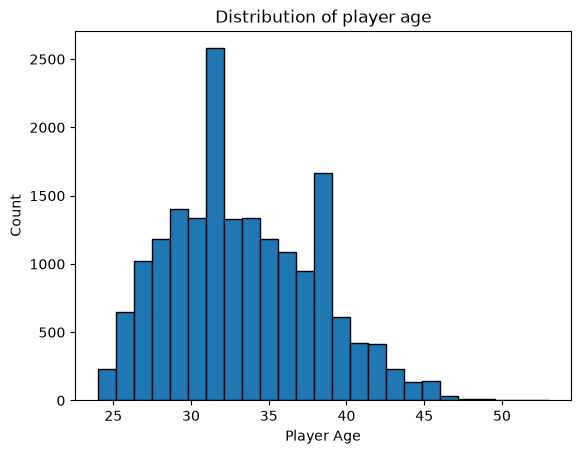

In [1564]:
""" Age Distribution """

min_age = round(players_df['age'].min(), 1)
max_age = round(players_df['age'].max(), 1)
avg_age = round(players_df['age'].mean(), 1)
med_age = round(players_df['age'].median(), 1)

print(f"Youngest: {min_age}\nOldest: {max_age}\nMean: {avg_age}\nMedian: {med_age}")

plt.hist(players_df['age'], bins=25, edgecolor='black')
plt.title("Distribution of player age")
plt.xlabel("Player Age")
plt.ylabel("Count")


In [1565]:
# possibly calculate average team age for teams participating in a given year of the WC tournament

Text(0.5, 0, 'Market Value')

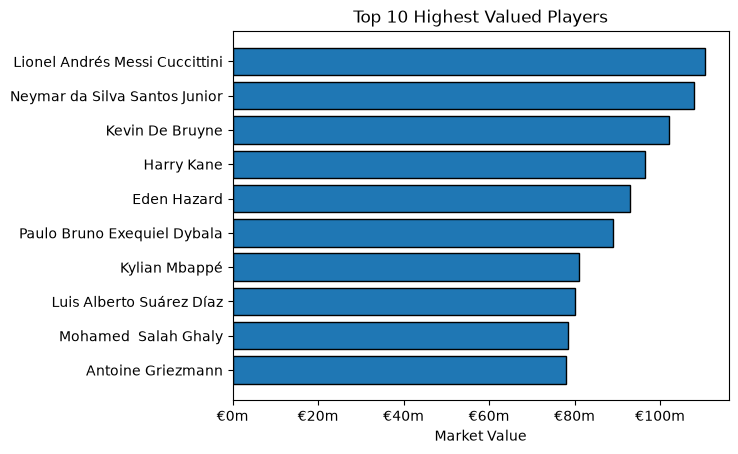

In [1566]:
''' Top 10 valued players'''

top_10_valued = players_df.nlargest(10, 'value_euro')
categories = top_10_valued['full_name']
values = top_10_valued['value_euro']
plt.barh(categories, values, edgecolor='black')
plt.gca().invert_yaxis()
plt.title('Top 10 Highest Valued Players')
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'€{x/1000000:.0f}m'))
plt.xlabel('Market Value')

# calculate the sum of the market value for all players in a given team for a particular year of the WC tournament

In [1567]:
''' Most common nationality of the top 10 valued players '''
mode_nationality = top_10_valued.groupby('nationality').agg(no_of_top_players=('nationality', 'count')).sort_values(by='no_of_top_players', ascending=False)
mode_nationality

,no_of_top_players
nationality,
Argentina,2
Belgium,2
France,2
Brazil,1
Egypt,1
England,1
Uruguay,1


In [1568]:
''' Top 3 rated players per country and their averages'''

best_players = players_df.sort_values(by='overall_rating', ascending=False)\
    .groupby('nationality').head(3)\
    .groupby('nationality').agg(players=('name', list),\
     ratings=('overall_rating', list), top_players_average=('overall_rating', 'mean')).sort_values(by='top_players_average', ascending=False)

best_players.head(10)

,players,ratings,top_players_average
nationality,,,
Argentina,"[L. Messi, P. Dybala, S. Agüero]","[94, 89, 89]",90.666667
Belgium,"[K. De Bruyne, E. Hazard, T. Courtois]","[91, 91, 89]",90.333333
Spain,"[De Gea, Sergio Ramos, David Silva]","[91, 90, 90]",90.333333
Uruguay,"[L. Suárez, D. Godín, E. Cavani]","[91, 90, 89]",90.000000
Brazil,"[Neymar Jr, Thiago Silva, Coutinho]","[92, 88, 88]",89.333333
Germany,"[T. Kroos, M. Neuer, M. ter Stegen]","[90, 89, 89]",89.333333
France,"[N. Kanté, A. Griezmann, K. Mbappé]","[89, 89, 88]",88.666667
Italy,"[G. Chiellini, G. Buffon, L. Insigne]","[90, 88, 88]",88.666667
Portugal,"[Cristiano Ronaldo, Bernardo Silva, A. Lopes]","[94, 86, 85]",88.333333


In [1569]:
'''Mean player rating by national team'''
overall_ratings = players_df.groupby('national_team').agg(mean_player_rating=('overall_rating', 'mean')).sort_values(by='mean_player_rating', ascending=False)
rounded_ratings = round(overall_ratings, 2).head(10)
rounded_ratings

,mean_player_rating
national_team,
Spain,84.48
Germany,84.04
Belgium,83.42
France,83.30
Dalian YiFang FC,83.00
FC Porto,82.20
Argentina,82.12
Italy,81.50
England,81.26


In [1570]:
# median player rating

med_rating = round(players_df['overall_rating'].median(), 1)
print(med_rating)

66.0


In [1571]:
finals_winners

,years,count
match_winner,,
Brazil,"[1958, 1962, 1970, 1994, 2002]",5
Germany,"[1954, 1974, 1990, 2014]",4
Italy,"[1934, 1938, 1982, 2006]",4
Argentina,"[1978, 1986, 2022]",3
Uruguay,"[1930, 1950]",2
France,"[1998, 2018]",2
England,[1966],1
Spain,[2010],1


In [1572]:
winning_teams = finals_winners.index

# player average for each team

national_teams = list(players_df['national_team'].unique().dropna())
print(winning_teams)
print(national_teams)

rating_mean = (players_df.groupby('national_team')['overall_rating'].mean())
winners_means = {}

for team in winning_teams:
    if team in rating_mean.index:
        winners_means[team] = rating_mean.loc[team]

print(winners_means)

winners_means = winners_means.values()

Index(['Brazil', 'Germany', 'Italy', 'Argentina', 'Uruguay', 'France',
       'England', 'Spain'],
      dtype='str', name='match_winner')
['Argentina', 'Denmark', 'France', 'Italy', 'Netherlands', 'Germany', 'Uruguay', 'Spain', 'Belgium', 'Egypt', 'Colombia', 'Sporting CP', 'Portugal', 'Dalian YiFang FC', 'Mexico', 'Brazil', 'England', 'Austria', 'Al Hilal', 'Iceland', 'Hungary', 'Wales', 'Cameroon', "Côte d'Ivoire", 'Australia', 'FC Porto', 'Romania', 'Russia', 'Chile', 'Norway', 'Peru', 'Venezuela', 'Sweden', 'Scotland', 'Canada', 'SL Benfica', 'Poland', 'Turkey', 'Northern Ireland', 'Santos Laguna', 'New Zealand', 'United States', 'Republic of Ireland', 'Ecuador', 'Pachuca', 'Slovenia', 'Czech Republic', 'Racing Club', 'FC Red Bull Salzburg', 'Puebla FC', 'Greece', 'Universidad de Chile', 'Club Tijuana', 'Paraguay', 'Switzerland', 'Querétaro', 'South Africa', 'Cruz Azul', 'BSC Young Boys', 'Atlético Nacional', 'Finland', 'Melbourne Victory', 'Independiente Santa Fe', 'Deportes Toli

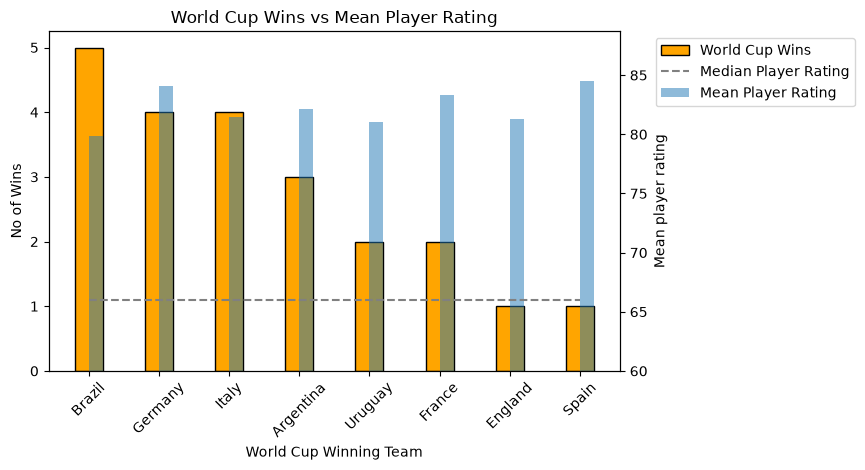

In [1573]:
# correlate world_cup_winners vs mean player rating for that national team 

fig, ax1 = plt.subplots()

# Bar plot - world cup wins
ax1.bar(finals_winners.index, finals_winners['count'], edgecolor='black', color='orange', width=0.4, align='center', label='World Cup Wins')
ax1.set_xlabel("World Cup Winning Team")
ax1.set_ylabel("No of Wins")
plt.xticks(rotation=45, fontsize=10)
plt.title("World Cup Wins vs Mean Player Rating")
plt.tight_layout()

# Bar plot - mean player rating (secondary axis)
x = winning_teams
y = winners_means
ax2 = ax1.twinx()
ax2.bar(winning_teams, winners_means, alpha=0.5, width=0.2, align='edge', label='Mean Player Rating')
ax2.set_ylabel('Mean player rating')
ax2.set_ylim(bottom=60)

# Line plot - median overall player rating (secondary axis)
med_ratings = np.repeat(med_rating, len(x))
ax2.plot(x, med_ratings, color='gray', linestyle='--', label='Median Player Rating')

handles, labels = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(handles + handles2, labels + labels2, bbox_to_anchor=(1.05, 1), loc='upper left')

## 8. Correlation Analysis

In [1574]:
players_df_copy = players_df.copy()
players_df_copy = players_df_copy.select_dtypes(include=np.number)
players_df_copy.head()

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,39,170.18,72.1,94,94,110500000.0,565000.0,5,4,4,...,94,48,22,94,94,75,96,33,28,26
1,34,154.94,76.2,88,89,69500000.0,205000.0,3,5,4,...,89,46,56,84,91,67,88,59,57,22
2,33,190.50,83.9,88,91,73000000.0,255000.0,4,4,5,...,82,78,64,82,88,82,87,63,67,67
3,35,162.56,59.0,88,88,62000000.0,165000.0,3,4,4,...,84,34,26,83,87,61,83,51,24,22
4,35,187.96,88.9,88,91,60000000.0,135000.0,3,3,2,...,15,87,88,24,49,33,80,91,88,87


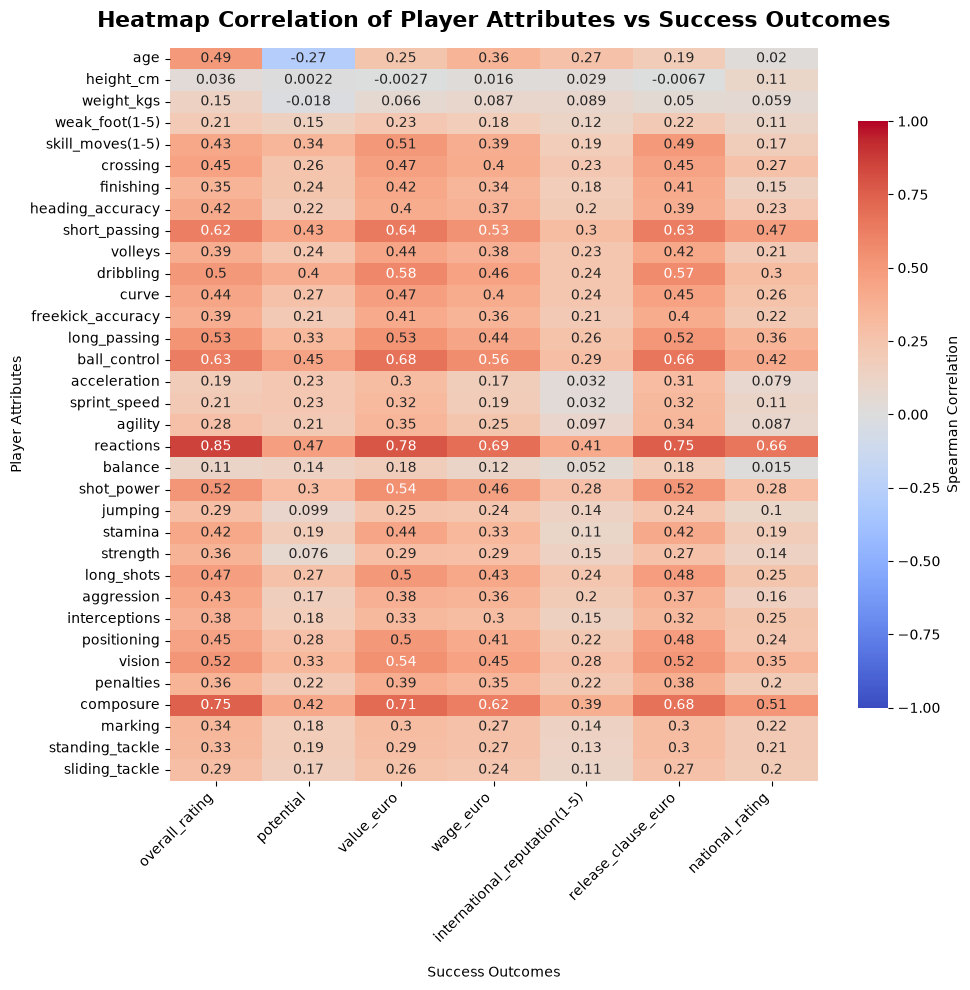

In [1575]:
skills_attributes = players_df_copy.drop(columns=[ 'overall_rating', \
                                               'potential', 'value_euro', 'wage_euro', 'international_reputation(1-5)', \
                                                'release_clause_euro', 'national_rating', 'national_jersey_number'])

outcomes = players_df_copy[['overall_rating', 'potential', 'value_euro', 'wage_euro', 'international_reputation(1-5)', 'release_clause_euro', 'national_rating']]


label_data = []
spearman_data = []
temporary_list = []
spearman_scores = {}
empty_df = pd.DataFrame( index=skills_attributes.columns, columns = outcomes.columns)
previous_skill = None
for skill in skills_attributes.columns:
    for outcome in outcomes.columns:
        current_skill = skills_attributes[skill]
        current_outcome = outcomes[outcome]
        new_df = pd.DataFrame({str(skill): current_skill,
                               str(outcome): current_outcome})
        new_df.dropna(inplace=True)                
        current_score = (stats.spearmanr(new_df[skill], new_df[outcome]))
        empty_df.at[skill, outcome] = current_score.statistic


spearmans_df = empty_df.astype(np.float64)
fig, ax = plt.subplots(figsize=(10,10))
plot = sns.heatmap(spearmans_df, cmap='coolwarm', cbar_kws={'shrink': 0.8, 'label': 'Spearman Correlation'}, center=0, vmin=-1,vmax=1,annot=True)
ax.set_title("Heatmap Correlation of Player Attributes vs Success Outcomes", fontsize=16, pad=15, fontweight='bold')
ax.set_xlabel("Success Outcomes", labelpad=15)
ax.tick_params(axis='x', rotation=45)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
ax.set_ylabel("Player Attributes")
plt.tight_layout()

- The heatmap shows that reactions vs overall_rating had the highest positive correlation, indicating that players with faster reaction times were rated more highly.  
- Reactions were fairly positively correlated against the other success outcomes such as player value, and national rating.
- Player age and potential were weakly negatively correlated, indicating that younger players were deemed as having more potential than older players.  
- Composure, ball control, short passing versus success outcomes were the next three characteristics which were fairly positively correlated but not to a large extent.
- Most other characteristics were weakly or neutrally correlated with success outcomes.


## 9. Additional Exploratory Analysis

In [1576]:
highest_valued_players = mv_df.sort_values(by='value', ascending=False)
top_50_valued = highest_valued_players.head(50)
merged_valued_profiles = pd.merge(top_50_valued, profiles_df, on='player_id', how='inner')
merged_valued_profiles = merged_valued_profiles.drop_duplicates(subset='player_name')
player_names = merged_valued_profiles[['player_name', 'citizenship']]
player_names

,player_name,citizenship
0,Vinicius Junior (371998),Brazil Spain
2,Kylian Mbappé (342229),France Cameroon
5,Lamine Yamal (937958),Spain Equatorial Guinea
6,Erling Haaland (418560),Norway
8,Neymar (68290),Brazil
13,Jude Bellingham (581678),England Ireland
17,Lionel Messi (28003),Argentina Spain
36,Raheem Sterling (134425),England Jamaica
46,Harry Kane (132098),England Ireland
48,Sadio Mané (200512),Senegal


In [1577]:
'''most caps'''
most_caps = perform_df.groupby(['player_id']).count().sort_values(by='player_id', ascending=False)
most_caps.head(5)

,season_name,competition_id,competition_name,team_id,team_name,nb_in_group,nb_on_pitch,goals,assists,own_goals,subed_in,subed_out,yellow_cards,second_yellow_cards,direct_red_cards,penalty_goals,minutes_played,goals_conceded,clean_sheets
player_id,,,,,,,,,,,,,,,,,,,
1453181,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452964,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452836,2,2,2,2,2,2,2,1,2,2,2,2,2,2,2,2,1,2,2
1452157,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452156,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2


In [1578]:
# id's of players with most minutes played

most_mins_played = (perform_df.groupby(['player_id', 'team_name'])['minutes_played'].sum().sort_values(ascending=False).head(50).reset_index())
most_mins_played.head()

,player_id,team_name,minutes_played
0,22415,Cruzeiro Esporte Clube,80748.0
1,15570,CSKA Moscow,72375.0
2,27796,Kashima Antlers,67196.0
3,3979,Real Madrid,64942.0
4,50144,Sport Club Corinthians Paulista,62143.0


In [1579]:
# player_id's of most mins played:
most_mins_players = most_mins_played['player_id']

In [1580]:
# player names using player ids
matching_rows = pd.merge(most_mins_players, profiles_df, on='player_id', how='inner')
names = matching_rows[['player_name', 'citizenship']]
names

# split citizenship if 2 spaces between country names, and keep the first one (birth citizenship)

def remove_last_country(lst):
    '''Removes last country name in list if there is more than 1'''
    if len(lst) > 1:
        lst.pop()
    return lst

names['citizenship'] = names['citizenship'].str.split('  ').apply(remove_last_country)
names['citizenship'] = (names['citizenship']).str[0]
names.head()

,player_name,citizenship
0,Fábio (22415),Brazil
1,Igor Akinfeev (15570),Russia
2,Hitoshi Sogahata (27796),Japan
3,Iker Casillas (3979),Spain
4,Cássio (50144),Brazil


In [1581]:
'''most common citizenship of players with most play-time'''

mode_citizenship_play = names.groupby('citizenship').agg(player_names=('player_name', list), count=('player_name', 'count')).sort_values(by='count', ascending=False)
mode_citizenship_play.head()

,player_names,count
citizenship,,
Germany,"[Oliver Kahn (206), Martin Männel (39096), Man...",6
Brazil,"[Fábio (22415), Cássio (50144), Magrão (55304)...",6
France,"[Steve Mandanda (23951), Hugo Lloris (17965), ...",4
England,"[Paul Harrison (22229), Kevin Pressman (10242)...",3
Spain,"[Iker Casillas (3979), David de Gea (59377), V...",3


In [1582]:
most_caps_players = pd.merge(most_caps, profiles_df, on='player_id', how='inner')
names_most_caps = most_caps_players[['player_name', 'citizenship']]
names_most_caps

,player_name,citizenship
0,Modou Jassey (1453181),Italy
1,Simone Meriggi (1452964),Italy
2,Santino Perrone (1452836),Italy
3,Bünyamin Oklu (1452157),Türkiye
4,Hasan Dağlı (1452156),Türkiye
...,...,...
88370,Petr Gabriel (5),Czech Republic
88371,Youri Djorkaeff (4),France Armenia
88372,Andreas Buck (3),Germany
88373,Mario Basler (2),Germany


In [1583]:
'''most common citizenship of players with most caps'''
mode_citizenship_caps = names_most_caps.groupby('citizenship').agg(player_names=('player_name', list), count=('player_name', 'count')).sort_values(by='count', ascending=False)
mode_citizenship_caps.head(10)

,player_names,count
citizenship,,
Italy,"[Modou Jassey (1453181), Simone Meriggi (14529...",11146
Spain,"[Lamine Gueye (1434744), Haitz Huete Gómez (14...",5672
Brazil,"[Neto (1422478), Willian Silva (1390655), Davi...",5368
England,"[Charlie Warren (1416999), Caleb Sanders (1407...",3987
France,"[Maxime Murer (1416886), Paul Bougrat (1412163...",3496
Germany,"[Caner Ari (1434540), Fabio Lettieri (1399703)...",3130
Türkiye,"[Bünyamin Oklu (1452157), Hasan Dağlı (1452156...",2938
Portugal,"[Henrique Lopes (1431410), Carlos Daniel (1426...",2034
Argentina,"[Lucas Medina (1408539), Isaias Penida (138645...",1829


In [1584]:
players_df.head(10)
unique_nations = list(players_df['nationality'].unique())
nationality_dfs = [(players_df[players_df['nationality'] == nation]).copy() for nation in unique_nations]

nationality_dfs[0]

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,39,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
7,S. Agüero,Sergio Leonel Agüero del Castillo,1988-06-02,38,172.72,69.9,ST,Argentina,89,89,...,83,65,24,92,83,83,90,30,20,12
15,P. Dybala,Paulo Bruno Exequiel Dybala,1993-11-15,33,152.40,74.8,"CAM,RW",Argentina,89,94,...,88,48,32,84,87,86,84,23,20,20
18,G. Higuaín,Gonzalo Gerardo Higuaín,1987-12-10,39,185.42,88.9,ST,Argentina,87,87,...,80,50,20,92,74,70,86,35,22,18
31,M. Icardi,Mauro Emanuel Icardi Rivero,1993-02-19,33,154.94,74.8,ST,Argentina,87,90,...,70,56,22,92,64,82,85,45,24,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17770,F. Vázquez,Franco Vázquez,1989-02-22,37,185.42,82.1,"CAM,CM,RW,LW",Argentina,82,82,...,84,78,54,77,84,67,80,46,40,37
17842,A. Gómez,Alejandro Darío Gómez,1988-02-15,38,165.10,68.0,"CF,LW,ST",Argentina,84,84,...,79,56,40,81,85,72,84,50,30,34
17849,E. Banega,Éver Maximiliano David Banega,1988-06-29,38,175.26,71.2,"CM,CAM,CDM",Argentina,84,84,...,78,73,76,75,88,78,80,75,70,66
17861,N. Otamendi,Nicolás Hernán Otamendi,1988-02-12,38,182.88,81.2,CB,Argentina,84,84,...,56,91,83,51,53,45,80,83,84,84


In [1585]:
all_positions = players_df["positions"].str.split(",")
list_of_positions = []

for pos in all_positions:
    list_of_positions.extend(pos)
unique_positions = set(list_of_positions)
unique_positions

{'CAM',
 'CB',
 'CDM',
 'CF',
 'CM',
 'GK',
 'LB',
 'LM',
 'LW',
 'LWB',
 'RB',
 'RM',
 'RW',
 'RWB',
 'ST'}

anything mid; anything with M
anything back; anything with B (means back)
anything wing; anything with W (means wing)
striker (ST); annything that is ST or has F (f is forward)
goaly (GK)

make a new column with simplified positional categories
1. Forward
2. Midfield
3. Defence
4. Goaly

couple rules:
if ST is present - ALWAYS a forward
if wing of any kind and have nothing else midfield
if wing and other assume the other
if GK present - ALWAYS a goaly

all other cases
count ocurrences of F, M, B

'CAM',2
'CB',1
'CDM',2
'CF', 3
'CM', 2
'GK', 0
'LB', 1
'LM', 2
'LW', 2
'LWB',1
'RB', 1
'RM', 2
'RW', 2
'RWB', 1
'ST' 3


In [1586]:
players_df['positions'] = players_df['positions'].str.split(',')

In [1587]:
players_df['positions'] 

0         [CF, RW, ST]
1        [CAM, RM, CM]
2            [CM, CAM]
3             [LW, ST]
4                 [CB]
             ...      
17949    [RM, CAM, CM]
17950             [LB]
17951             [GK]
17952         [ST, LM]
17953             [ST]
Name: positions, Length: 17954, dtype: object

In [1588]:
''' make values in positions column into lists'''

def get_pos_number(positions):
    '''takes abbreviated positions and assigns a numeric score 
    depending on whether the position is forward, midfield, defence, or goalkeeping'''
    scores = []
    for position in positions:
        if position in ['CF', 'ST']:
            scores.append(3)
        elif position in ['CAM', 'CDM', 'CM', 'LM', 'LW', 'RM', 'RW']:
            scores.append(2)
        elif position in ['CB', 'LB', 'LWB', 'RWB']:
            scores.append(1)
        elif position in ['GK']:
            scores.append(0)
    return scores

players_df['position_as_number'] = players_df['positions'].apply(get_pos_number)
players_df['position_as_number']

0        [3, 2, 3]
1        [2, 2, 2]
2           [2, 2]
3           [2, 3]
4              [1]
           ...    
17949    [2, 2, 2]
17950          [1]
17951          [0]
17952       [3, 2]
17953          [3]
Name: position_as_number, Length: 17954, dtype: object

In [1589]:
'''get the mean then assign categories: 
if <1.6666 they are DEFENCE
if >=1.6667  they are MIDFIELD
if >= 2.3333 they are FORWARD
if <1 they are GOALY'''

players_df['mean_position'] = players_df['position_as_number']\
.apply(lambda x: 'Forward' if np.array(x).mean() >= 2.3 \
       else 'Midfield' if np.array(x).mean() >= 1.6 else 'Defense' if np.array(x).mean() else 'Goalkeeper')

C:\Users\bevamin\AppData\Local\Temp\ipykernel_27296\414569747.py:8: RuntimeWarning: Mean of empty slice
  .apply(lambda x: 'Forward' if np.array(x).mean() >= 2.3 \
C:\Users\bevamin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\bevamin\AppData\Local\Temp\ipykernel_27296\414569747.py:9: RuntimeWarning: Mean of empty slice
  else 'Midfield' if np.array(x).mean() >= 1.6 else 'Defense' if np.array(x).mean() else 'Goalkeeper')


In [1590]:
player_agg_df = players_df[players_df['nationality'].isin(finals_winners.index)]
player_agg_df_filtered = player_agg_df.groupby(['nationality', 'mean_position']).agg(count=('position_as_number', 'count'))
player_agg_df_grouped = player_agg_df_filtered.groupby('mean_position').agg(lambda x: list(x))
player_agg_df_filtered

count
nationality mean_position       
Argentina   Defense          282
            Forward          173
            Goalkeeper        96
            Midfield         353
Brazil      Defense          283
            Forward          173
            Goalkeeper        73
            Midfield         303
England     Defense          562
            Forward          324
            Goalkeeper       179
            Midfield         593
France      Defense          309
            Forward          162
            Goalkeeper       104
            Midfield         350
Germany     Defense          421
            Forward          183
            Goalkeeper       162
            Midfield         433
Italy       Defense          211
            Forward          119
            Goalkeeper        95
            Midfield         230
Spain       Defense          351
            Forward          165
            Goalkeeper       120
            Midfield         434
Uruguay     Defense           45
            Forward           30
            Goalkeeper        12
            Midfield          48

In [1591]:
transposed = player_agg_df_grouped.T
transposed

mean_position,Defense,Forward,Goalkeeper,Midfield
count,"[282, 283, 562, 309, 421, 211, 351, 45]","[173, 173, 324, 162, 183, 119, 165, 30]","[96, 73, 179, 104, 162, 95, 120, 12]","[353, 303, 593, 350, 433, 230, 434, 48]"


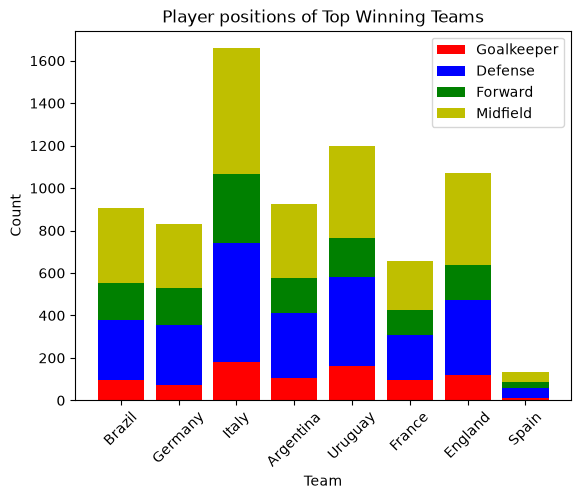

In [1592]:
'''x and y values'''
x = finals_winners.index
y1 = np.asarray(transposed['Goalkeeper'].to_numpy()[0])
y2 = np.asarray(transposed['Defense'].to_numpy()[0])
y3 = np.asarray(transposed['Forward'].to_numpy()[0])
y4 = np.asarray(transposed['Midfield'].to_numpy()[0])


'''stacked bar of player market values depending on their group against nationality, position'''
plt.bar(x, y1, color='r')
plt.bar(x, y2, color='b', bottom=y1)
plt.bar(x, y3, color='g', bottom=y1+y2)
plt.bar(x, y4, color='y', bottom=y1+y2+y3)
plt.title('Player positions of Top Winning Teams')
plt.legend(['Goalkeeper', 'Defense', 'Forward', 'Midfield'])
plt.xlabel('Team')
plt.xticks(rotation=45)
plt.ylabel('Count')
plt.show()
# add median line?

In [1593]:
mins_played = perform_df.sort_values(by='minutes_played', ascending=False)
top_mins = mins_played[['player_id', 'minutes_played']].head(50).reset_index()
top_mins_players = pd.merge(top_mins, profiles_df, how='inner', on='player_id')
top_mins_players.head()

,index,player_id,minutes_played,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,...,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death,age
0,148243,126383,4590.0,takuto-hayashi,Takuto Hayashi (126383),https://img.a.transfermarkt.technology/portrai...,林 卓人,1982-08-09,"Ibaraki, Osaka",Japan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.0
1,1676197,79333,4590.0,yosuke-nozawa,Yosuke Nozawa (79333),https://img.a.transfermarkt.technology/portrai...,野澤 洋輔,1979-11-09,"Shizuoka, Shizuoka",Japan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.0
2,108819,118487,4411.0,jin-hyeon-kim,Jin-hyeon Kim (118487),https://img.a.transfermarkt.technology/portrai...,김진현,1987-07-06,"Suwon, Gyeonggi","Korea, South",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.0
3,1676216,79333,4410.0,yosuke-nozawa,Yosuke Nozawa (79333),https://img.a.transfermarkt.technology/portrai...,野澤 洋輔,1979-11-09,"Shizuoka, Shizuoka",Japan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.0
4,1380814,584978,4342.0,katsumi-suzuki,Katsumi Suzuki (584978),https://img.a.transfermarkt.technology/portrai...,NaN,1969-04-21,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57.0


In [1594]:
goal_scorers = perform_df.sort_values(by='goals', ascending=False)
top_scorers = goal_scorers[['player_id', 'goals']].head(50).reset_index()
top_scoring_players = pd.merge(top_scorers, profiles_df, how='inner', on='player_id')
top_scoring_players.head()

,index,player_id,goals,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,...,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death,age
0,666846,28003,50.0,lionel-messi,Lionel Messi (28003),https://img.a.transfermarkt.technology/portrai...,Lionel Andrés Messi Cuccitini,1987-06-24,Rosario,Argentina,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.0
1,439342,202867,50.0,maik-lukowicz,Maik Lukowicz (202867),https://img.a.transfermarkt.technology/portrai...,Michał Łukowicz,1995-02-01,Bremen,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.0
2,1716008,8198,48.0,cristiano-ronaldo,Cristiano Ronaldo (8198),https://img.a.transfermarkt.technology/portrai...,Cristiano Ronaldo dos Santos Aveiro,1985-02-05,Funchal,Portugal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.0
3,398869,191202,48.0,danny-rowe,Danny Rowe (191202),https://img.a.transfermarkt.technology/portrai...,Daniel Lucas Rowe,1989-01-29,Blackpool,England,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.0
4,1145527,467720,46.0,youssoufa-moukoko,Youssoufa Moukoko (467720),https://img.a.transfermarkt.technology/portrai...,NaN,2004-11-20,Yaoundé,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.0


In [1595]:
goal_conceders = perform_df.sort_values(by='goals_conceded', ascending=False)
top_conceders = goal_conceders[['player_id', 'goals_conceded']].head(50).reset_index()
top_conceding_players = pd.merge(top_conceders, profiles_df, how='inner', on='player_id')
top_conceding_players.head()

,index,player_id,goals_conceded,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,...,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death,age
0,1479524,640613,111,dennis-preuschoff,Dennis Preuschoff (640613),https://img.a.transfermarkt.technology/portrai...,NaN,NaT,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1322131,55649,108,rene-monjeamb,René Monjeamb (55649),https://img.a.transfermarkt.technology/portrai...,NaN,1990-09-08,Köln,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.0
2,1726491,830333,104,mason-mccready,Mason McCready (830333),https://img.a.transfermarkt.technology/portrai...,NaN,2003-01-05,"Providence, Rhode Island",Scotland,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0
3,534313,234253,95,matteo-forzati,Matteo Forzati (234253),https://img.a.transfermarkt.technology/portrai...,NaN,1995-07-23,Latina,Italy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.0
4,1795311,908544,92,lukas-peterson,Lukas Peterson (908544),https://img.a.transfermarkt.technology/portrai...,NaN,2003-10-07,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0


Which attributes drive performance?
goals_per_90
assists_per_90
goal_contributions_per_90


compare across:
height
position
footedness
age
market value


Example insights:
Expensive forwards score more per 90
Height helps strikers but hurts midfielders
Left-footed players are overrepresented among high-value attackers

In [1596]:
print(profiles_df.columns)
print(perform_df.columns)
print(players_df.columns)
print(comps_df.columns)

Index(['player_id', 'player_slug', 'player_name', 'player_image_url',
       'name_in_home_country', 'date_of_birth', 'place_of_birth',
       'country_of_birth', 'height', 'citizenship', 'is_eu', 'position',
       'main_position', 'foot', 'current_club_id', 'current_club_name',
       'joined', 'contract_expires', 'outfitter', 'social_media_url',
       'player_agent_id', 'player_agent_name', 'contract_option',
       'date_of_last_contract_extension', 'on_loan_from_club_id',
       'on_loan_from_club_name', 'contract_there_expires', 'second_club_url',
       'second_club_name', 'third_club_url', 'third_club_name',
       'fourth_club_url', 'fourth_club_name', 'date_of_death', 'age'],
      dtype='str')
Index(['player_id', 'season_name', 'competition_id', 'competition_name',
       'team_id', 'team_name', 'nb_in_group', 'nb_on_pitch', 'goals',
       'assists', 'own_goals', 'subed_in', 'subed_out', 'yellow_cards',
       'second_yellow_cards', 'direct_red_cards', 'penalty_goals',
   

In [1597]:
''' players with highest count of comp ids? group by player/nationaility'''

comps_df['competition_name'].unique()

<StringArray>
[                                  '3. Liga',
                      'Regionalliga Südwest',
               'Regionalliga West (- 11/12)',
                'Oberliga Südwest (- 11/12)',
                'Oberliga Südwest (- 07/08)',
          'Regionalliga Süd (94/95 - 07/08)',
                             '2. Bundesliga',
 'Regionalliga West-Südwest (94/95 - 99/00)',
                                'Bundesliga',
                       '2. Bundesliga South',
 ...
 '2. Liga interregional - Group 5 (- 11/12)',
 '2. Liga interregional - Group 3 (- 11/12)',
    'China League Two B (Division Yancheng)',
                    'China League Two North',
                            'Burgenlandliga',
                   '1. Klasse Lower Austria',
                                'Bremenliga',
             'Eliteliga Vorarlberg (- 2023)',
                            'Vorarlbergliga',
                           'Niederrheinliga']
Length: 569, dtype: str

In [1598]:
player_vs_country = players_df.groupby('nationality')\
.agg(avg_market_value=('value_euro', 'mean'), avg_player_rating=('overall_rating', 'mean'), no_players=('name', 'count'))\
.sort_values(by=['no_players', 'avg_market_value'], ascending=False)

player_vs_country.head()

,avg_market_value,avg_player_rating,no_players
nationality,,,
England,1.543341e+06,63.554282,1658
Germany,2.553841e+06,66.143453,1199
Spain,4.324014e+06,69.614953,1070
France,3.779140e+06,67.856216,925
Argentina,3.211847e+06,68.667035,904


In [1599]:
# Aggregate performance per player
player_perf_agg = perform_df.groupby('player_id').agg(goals=('goals', 'sum'), assists=('assists', 'sum'), minutes=('minutes_played', 'sum')).reset_index()

# Remove players with very low minutes
player_perf_agg = player_perf_agg[player_perf_agg['minutes'] >= 900]

# Calculate per-90 metrics
player_perf_agg['goals_per_90'] = (player_perf_agg['goals'] / player_perf_agg['minutes'] * 90)
player_perf_agg['assists_per_90'] = (player_perf_agg['assists'] / player_perf_agg['minutes'] * 90)
player_perf_agg['goal_contributions_per_90'] = ((player_perf_agg['goals'] + player_perf_agg['assists'])/ player_perf_agg['minutes'] * 90)

# Merge player attributes
perf_profiles = pd.merge(player_perf_agg, profiles_df, how='inner', on='player_id')

# Get latest market value per player
latest_market_values = mv_df.loc[mv_df.groupby('player_id')['date_unix'].idxmax()]
perf_profiles = pd.merge(perf_profiles, latest_market_values[['player_id', 'value']], how='left', on='player_id').rename(columns={'value': 'market_value'})
perf_profiles.replace([np.inf, -np.inf], np.nan, inplace=True)

print(perf_profiles.columns)
perf_profiles.sample(5)

Index(['player_id', 'goals', 'assists', 'minutes', 'goals_per_90',
       'assists_per_90', 'goal_contributions_per_90', 'player_slug',
       'player_name', 'player_image_url', 'name_in_home_country',
       'date_of_birth', 'place_of_birth', 'country_of_birth', 'height',
       'citizenship', 'is_eu', 'position', 'main_position', 'foot',
       'current_club_id', 'current_club_name', 'joined', 'contract_expires',
       'outfitter', 'social_media_url', 'player_agent_id', 'player_agent_name',
       'contract_option', 'date_of_last_contract_extension',
       'on_loan_from_club_id', 'on_loan_from_club_name',
       'contract_there_expires', 'second_club_url', 'second_club_name',
       'third_club_url', 'third_club_name', 'fourth_club_url',
       'fourth_club_name', 'date_of_death', 'age', 'market_value'],
      dtype='str')


,player_id,goals,assists,minutes,goals_per_90,assists_per_90,goal_contributions_per_90,player_slug,player_name,player_image_url,...,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death,age,market_value
60726,913659,0.0,0,5109.0,0.000000,0.000000,0.000000,axel-kedvesi,Axel Kedvesi (913659),https://img.a.transfermarkt.technology/portrai...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.0,NaN
31063,257459,11.0,5,1368.0,0.723684,0.328947,1.052632,wallyson,Wallyson (257459),https://img.a.transfermarkt.technology/portrai...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.0,0.0
53803,683112,9.0,1,2309.0,0.350801,0.038978,0.389779,halil-esen,Halil Esen (683112),https://img.a.transfermarkt.technology/portrai...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.0,100000.0
50290,604211,10.0,3,1634.0,0.550796,0.165239,0.716034,leonardo-trezza,Leonardo Trezza (604211),https://img.a.transfermarkt.technology/portrai...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,0.0
61543,935457,10.0,12,1345.0,0.669145,0.802974,1.472119,salim-el-jebari,Salim El Jebari (935457),https://img.a.transfermarkt.technology/portrai...,...,2027-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.0,400000.0


Text(0.5, 1.0, 'Player Position vs Goals Contributions per 90 Mins')

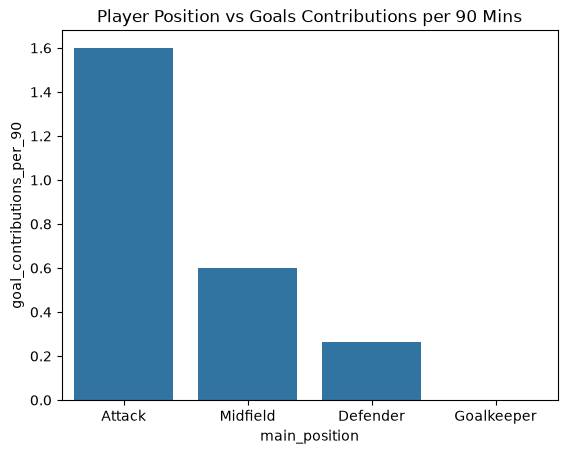

In [1600]:
'''Position vs Performance'''

position_v_perform = perf_profiles.groupby('main_position').agg(goals=('goals', 'sum'), assists=('assists', 'sum'), minutes=('minutes', 'sum'))
position_v_perform['goal_contributions_per_90'] = ((position_v_perform['goals'] + position_v_perform['assists']) / position_v_perform['minutes'] * 90)
position_v_perform = position_v_perform.sort_values('goal_contributions_per_90', ascending=False)


sns.barplot(data=position_v_perform, x='main_position', y='goal_contributions_per_90')
plt.title('Player Position vs Goals Contributions per 90 Mins')

,market_value,goal_contributions_per_90
market_value,1.000000,0.122269
goal_contributions_per_90,0.122269,1.000000


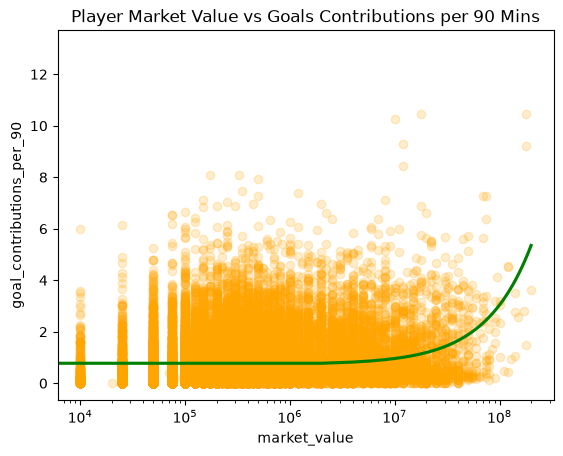

In [1601]:
'''Market Value vs Performance'''


ax = sns.regplot(data=perf_profiles, x='market_value', y='goal_contributions_per_90', ci=None, color="orange", marker="o", scatter_kws={'alpha':0.2}, line_kws={'color': 'green'})
plt.title('Player Market Value vs Goals Contributions per 90 Mins')
ax.set_xscale('log')
perf_profiles[['market_value', 'goal_contributions_per_90']].corr()

Text(0.5, 1.0, 'Player Height vs Goals Scored per 90 Mins')

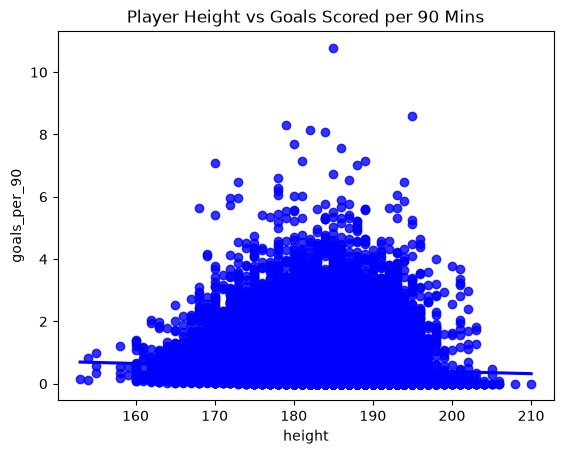

In [1602]:
'''Height vs Performance'''

# exclude players were height = 0 ie no data on their height, as this skewed the results massively

clean_for_height = perf_profiles[perf_profiles['height'] != 0]

sns.regplot(data=clean_for_height, x='height', y='goals_per_90', ci=None, color="blue", marker="o")
plt.title('Player Height vs Goals Scored per 90 Mins')

Text(0.5, 1.0, 'Player Age vs Goals Scored per 90 Mins')

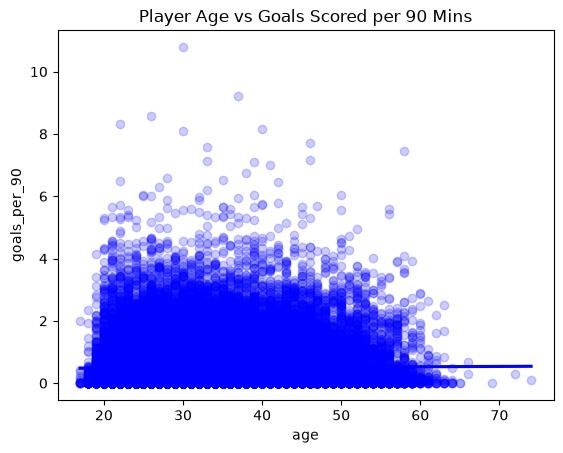

In [1603]:
''' Age vs Performance '''

sns.regplot(data=perf_profiles, x='age', y='goals_per_90', ci=None, color="blue", marker="o", scatter_kws={'alpha': 0.2})
plt.title('Player Age vs Goals Scored per 90 Mins')

In [1604]:
fp9 = Path.cwd().parent/'data'/'squads.csv'
squads = pd.read_csv(fp9)

fp10 = Path.cwd().parent/'data'/'players.csv'
players = pd.read_csv(fp10)

fp11 = Path.cwd().parent/'data'/'goals.csv'
goals = pd.read_csv(fp11)

fp12 = Path.cwd().parent/'data'/'qualified_teams.csv'
quali_teams = pd.read_csv(fp12)

fp13 = Path.cwd().parent/'data'/'tournaments.csv'
tournaments = pd.read_csv(fp13)

fp14 = Path.cwd().parent/'data'/'manager_appointments.csv'
managers = pd.read_csv(fp14)

fp15 = Path.cwd().parent/'data'/'substitutions.csv'
subs = pd.read_csv(fp15)

fp16 = Path.cwd().parent/'data'/'host_countries.csv'
hosts = pd.read_csv(fp16)

fp17 = Path.cwd().parent/'data'/'penalty_kicks.csv'
penalties = pd.read_csv(fp17)


In [1605]:
mask = subs["tournament_name"].str.contains("Women")
subs = subs[~mask]
subs.head(20)

,key_id,substitution_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,player_id,family_name,given_name,shirt_number,minute_label,minute_regulation,minute_stoppage,match_period,going_off,coming_on
0,1,S-0001,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-72,...,P-60181,Serebryanikov,Viktor,15,46',46,0,second half,1,0
1,2,S-0002,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-72,...,P-59828,Puzach,Anatoliy,20,46',46,0,second half,0,1
2,3,S-0003,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-72,...,P-43733,Nodia,Givi,19,66',66,0,second half,1,0
3,4,S-0004,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-72,...,P-98262,Khmelnitsky,Vitaly,21,66',66,0,second half,0,1
4,5,S-0005,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-46,...,P-32657,Velarde,Mario,18,67',67,0,second half,1,0
5,6,S-0006,WC-1970,1970 FIFA Men's World Cup,M-1970-01,Mexico vs Soviet Union,1970-05-31,group stage,Group 1,T-46,...,P-96873,Munguía,Antonio,8,67',67,0,second half,0,1
6,7,S-0007,WC-1970,1970 FIFA Men's World Cup,M-1970-02,Uruguay vs Israel,1970-06-02,group stage,Group 2,T-84,...,P-47892,Rocha,Pedro,8,12',12,0,first half,1,0
7,8,S-0008,WC-1970,1970 FIFA Men's World Cup,M-1970-02,Uruguay vs Israel,1970-06-02,group stage,Group 2,T-84,...,P-82186,Cortés,Julio César,20,12',12,0,first half,0,1
8,9,S-0009,WC-1970,1970 FIFA Men's World Cup,M-1970-02,Uruguay vs Israel,1970-06-02,group stage,Group 2,T-40,...,P-86314,Talbi,Rachamim,15,46',46,0,second half,1,0
9,10,S-0010,WC-1970,1970 FIFA Men's World Cup,M-1970-02,Uruguay vs Israel,1970-06-02,group stage,Group 2,T-40,...,P-08449,Bar,Shraga,2,46',46,0,second half,0,1


In [1606]:
subs_by_year_by_team = subs.groupby(["tournament_id", "team_name"]).agg(subs_count = ("substitution_id", "count"))
subs_by_year_by_team.reset_index(inplace=True)
subs_by_year_by_team[subs_by_year_by_team["tournament_id"] == "WC-2022"]

,tournament_id,team_name,subs_count
336,WC-2022,Argentina,72
337,WC-2022,Australia,38
338,WC-2022,Belgium,28
339,WC-2022,Brazil,50
340,WC-2022,Cameroon,24
341,WC-2022,Canada,30
342,WC-2022,Costa Rica,28
343,WC-2022,Croatia,64
344,WC-2022,Denmark,26
345,WC-2022,Ecuador,22


In [1607]:
squads.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,position_name,position_code
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,goal keeper,GK
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,goal keeper,GK
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,forward,FW
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,defender,DF
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,defender,DF


In [1608]:
players.head() # use player_id col to join

,key_id,player_id,family_name,given_name,birth_date,female,goal_keeper,defender,midfielder,forward,count_tournaments,list_tournaments,player_wikipedia_link
0,1,P-35894,A'Court,Alan,1934-09-30,0,0,0,0,1,1,1958,https://en.wikipedia.org/wiki/Alan_A%27Court
1,2,P-29915,Aarønes,Ann Kristin,1973-01-19,1,0,0,1,1,2,"1995, 1999",https://en.wikipedia.org/wiki/Ann_Kristin_Aar%...
2,3,P-03484,Aaronson,Brenden,2000-10-22,0,0,0,0,1,1,2022,https://en.wikipedia.org/wiki/Brenden_Aaronson
3,4,P-04189,Abadzhiev,Stefan,1934-07-03,0,0,0,0,1,1,1966,https://en.wikipedia.org/wiki/Stefan_Abadzhiev
4,5,P-03523,Abalo,Jean-Paul,1975-06-26,0,0,1,0,0,1,2006,https://en.wikipedia.org/wiki/Jean-Paul_Abalo


In [1609]:
goals.head()

,key_id,goal_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,shirt_number,player_team_id,player_team_name,player_team_code,minute_label,minute_regulation,minute_stoppage,match_period,own_goal,penalty
0,1,G-0001,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,19',19,0,first half,0,0
1,2,G-0002,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,40',40,0,first half,0,0
2,3,G-0003,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,43',43,0,first half,0,0
3,4,G-0004,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-46,...,0,T-46,Mexico,MEX,70',70,0,second half,0,0
4,5,G-0005,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,87',87,0,second half,0,0


In [1610]:
tournaments.head()

,key_id,tournament_id,tournament_name,year,start_date,end_date,host_country,winner,host_won,count_teams,group_stage,second_group_stage,final_round,round_of_16,quarter_finals,semi_finals,third_place_match,final
0,1,WC-1930,1930 FIFA Men's World Cup,1930,1930-07-13,1930-07-30,Uruguay,Uruguay,1,13,1,0,0,0,0,1,0,1
1,2,WC-1934,1934 FIFA Men's World Cup,1934,1934-05-27,1934-06-10,Italy,Italy,1,16,0,0,0,1,1,1,1,1
2,3,WC-1938,1938 FIFA Men's World Cup,1938,1938-06-04,1938-06-19,France,Italy,0,15,0,0,0,1,1,1,1,1
3,4,WC-1950,1950 FIFA Men's World Cup,1950,1950-06-24,1950-07-16,Brazil,Uruguay,0,13,1,0,1,0,0,0,0,0
4,5,WC-1954,1954 FIFA Men's World Cup,1954,1954-06-16,1954-07-04,Switzerland,West Germany,0,16,1,0,0,0,1,1,1,1


In [1611]:
quali_teams.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,count_matches,performance
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,5,final
1,2,WC-1930,1930 FIFA Men's World Cup,T-06,Belgium,BEL,2,group stage
2,3,WC-1930,1930 FIFA Men's World Cup,T-07,Bolivia,BOL,2,group stage
3,4,WC-1930,1930 FIFA Men's World Cup,T-09,Brazil,BRA,2,group stage
4,5,WC-1930,1930 FIFA Men's World Cup,T-13,Chile,CHL,3,group stage


In [1612]:
print(squads.columns)
print(players.columns)
print(goals.columns)
print(quali_teams.columns)
print(tournaments.columns)

Index(['key_id', 'tournament_id', 'tournament_name', 'team_id', 'team_name',
       'team_code', 'player_id', 'family_name', 'given_name', 'shirt_number',
       'position_name', 'position_code'],
      dtype='str')
Index(['key_id', 'player_id', 'family_name', 'given_name', 'birth_date',
       'female', 'goal_keeper', 'defender', 'midfielder', 'forward',
       'count_tournaments', 'list_tournaments', 'player_wikipedia_link'],
      dtype='str')
Index(['key_id', 'goal_id', 'tournament_id', 'tournament_name', 'match_id',
       'match_name', 'match_date', 'stage_name', 'group_name', 'team_id',
       'team_name', 'team_code', 'home_team', 'away_team', 'player_id',
       'family_name', 'given_name', 'shirt_number', 'player_team_id',
       'player_team_name', 'player_team_code', 'minute_label',
       'minute_regulation', 'minute_stoppage', 'match_period', 'own_goal',
       'penalty'],
      dtype='str')
Index(['key_id', 'tournament_id', 'tournament_name', 'team_id', 'team_name',
    

In [1613]:
tourn_winners_mens = tournaments[~tournaments['tournament_name'].str.contains('Women', case=False)]
tourn_winners_mens = tourn_winners_mens[['tournament_id', 'winner']]
tourn_winners_mens

,tournament_id,winner
0,WC-1930,Uruguay
1,WC-1934,Italy
2,WC-1938,Italy
3,WC-1950,Uruguay
4,WC-1954,West Germany
5,WC-1958,Brazil
6,WC-1962,Brazil
7,WC-1966,England
8,WC-1970,Brazil
9,WC-1974,West Germany


In [1614]:
winners_list = tourn_winners_mens['winner'].unique()
winners_list

<StringArray>
[     'Uruguay',        'Italy', 'West Germany',       'Brazil',
      'England',    'Argentina',       'France',        'Spain',
      'Germany']
Length: 9, dtype: str

In [1615]:
# exclude womens
mens_squads = squads[~squads['tournament_name'].str.contains('Women', case=False)]
mens_squads

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,position_name,position_code
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,goal keeper,GK
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,goal keeper,GK
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,forward,FW
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,defender,DF
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,defender,DF
...,...,...,...,...,...,...,...,...,...,...,...,...
13838,13839,WC-2022,2022 FIFA Men's World Cup,T-85,Wales,WAL,P-20564,Thomas,Sorba,22,midfielder,MF
13839,13840,WC-2022,2022 FIFA Men's World Cup,T-85,Wales,WAL,P-24982,Levitt,Dylan,23,midfielder,MF
13840,13841,WC-2022,2022 FIFA Men's World Cup,T-85,Wales,WAL,P-02030,Cabango,Ben,24,defender,DF
13841,13842,WC-2022,2022 FIFA Men's World Cup,T-85,Wales,WAL,P-07137,Colwill,Rubin,25,midfielder,MF


In [1616]:
mens_squads = pd.merge(mens_squads, players[['player_id', 'count_tournaments']], on='player_id', how='inner')
mens_squads = pd.merge(mens_squads, quali_teams[['team_id', 'tournament_id', 'performance', "count_matches"]], on=['team_id', 'tournament_id'], how='inner')
mens_squads = pd.merge(mens_squads, tournaments[['tournament_id', 'start_date']], on='tournament_id', how='inner')
mens_squads = pd.merge(mens_squads, subs_by_year_by_team, on=['tournament_id', 'team_name'], how='left')


In [1617]:
mens_squads.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,position_name,position_code,count_tournaments,performance,count_matches,start_date,subs_count
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,goal keeper,GK,1,final,5,1930-07-13,NaN
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,goal keeper,GK,1,final,5,1930-07-13,NaN
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,forward,FW,1,final,5,1930-07-13,NaN
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,defender,DF,1,final,5,1930-07-13,NaN
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,defender,DF,1,final,5,1930-07-13,NaN


In [1748]:
mens_squads['performance'].unique()

<StringArray>
[             'final',        'group stage',        'semi-finals',
        'round of 16',  'third-place match',     'quarter-finals',
        'final round', 'second group stage']
Length: 8, dtype: str

In [1618]:
performance_rank = {
    'group stage': 1,
    'round of 16': 2,
    'second group stage': 2,
    'quarter-finals': 3,
    'quarter-final': 3,
    'semi-finals': 4,
    'third-place match': 4,
    'final': 5
}

mens_squads['perform_rank'] = mens_squads['performance'].map(performance_rank)

In [1619]:
mens_squads['tournament_year'] = mens_squads['tournament_id'].map(lambda x: x[-4:])
mens_squads = pd.merge(mens_squads, players[['player_id', 'birth_date']], on='player_id', how='inner')
mens_squads['birth_date_dt'] = pd.to_datetime(mens_squads['birth_date'], format='%Y-%m-%d', errors='coerce')
mens_squads['start_date_dt'] = pd.to_datetime(mens_squads['start_date'], format='%Y-%m-%d', errors='coerce')
mens_squads['age'] = (mens_squads['start_date_dt'] - mens_squads['birth_date_dt']).dt.days / 365.25

In [1620]:
mens_squads.rename(columns={"count_matches": "team_total_matches"}, inplace=True)
mens_squads.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,...,performance,team_total_matches,start_date,subs_count,perform_rank,tournament_year,birth_date,birth_date_dt,start_date_dt,age
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,...,final,5,1930-07-13,NaN,5.0,1930,1905-05-05,1905-05-05,1930-07-13,25.188227
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,...,final,5,1930-07-13,NaN,5.0,1930,1908-10-23,1908-10-23,1930-07-13,21.719370
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,...,final,5,1930-07-13,NaN,5.0,1930,1907-02-23,1907-02-23,1930-07-13,23.383984
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,...,final,5,1930-07-13,NaN,5.0,1930,1907-02-23,1907-02-23,1930-07-13,23.383984
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,...,final,5,1930-07-13,NaN,5.0,1930,1906-03-23,1906-03-23,1930-07-13,24.306639


In [1621]:
# squad_performance = (mens_squads.groupby(['tournament_id', 'team_name'])['perform_rank']\
#                     .agg(avg_performance='mean',median_performance='median',max_performance='max').reset_index())
# squad_performance

In [1622]:
'''furthest stage reached for each team grouped over all time'''

squad_performance_all_time = (mens_squads.groupby('team_name')['perform_rank']\
                    .agg(avg_performance_alltime='mean',median_performance_alltime='median',max_performance_alltime='max').reset_index())
squad_performance_all_time.sort_values("avg_performance_alltime", ascending=False).head(5)


,team_name,avg_performance_alltime,median_performance_alltime,max_performance_alltime
82,West Germany,4.300000,5.0,5.0
8,Brazil,3.425532,3.0,5.0
45,Netherlands,3.361446,3.0,5.0
28,Germany,3.174672,3.0,5.0
2,Argentina,3.082294,3.0,5.0


In [1623]:
''' how many ganes did players play in each tournament (low avg = changing players a lot)'''

squad_experience = (mens_squads.groupby(['tournament_id', 'team_name', "team_total_matches"])\
                    .agg(avg_games_played=("count_tournaments", "mean"), median_games_played=("count_tournaments", "median")\
                         , max_games_played=("count_tournaments", "max"), round_reached= ("perform_rank", "max"), subs_count=("subs_count", "max")).reset_index())

#perform_rank
# squad_experience = pd.merge(squad_experience, mens_squads[["tournament_id", "team_name", "subs_count"]], on=["tournament_id", "team_name"], how="left")
squad_experience_2002 = squad_experience[squad_experience['tournament_id'] == 'WC-2002']
# squad_experience_2002.head(20)

In [1624]:
# squad_experience[squad_experience["team_name"] == "Argentina"]
squad_experience["subs_per_game"] = (squad_experience["subs_count"] / squad_experience["team_total_matches"]) / 2
squad_experience.tail(50)

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game
439,WC-2018,Japan,4,1.956522,2.0,4,2.0,22.0,2.750000
440,WC-2018,Mexico,4,2.565217,2.0,5,2.0,24.0,3.000000
441,WC-2018,Morocco,3,1.347826,1.0,2,1.0,18.0,3.000000
442,WC-2018,Nigeria,3,1.260870,1.0,2,1.0,18.0,3.000000
443,WC-2018,Panama,3,1.000000,1.0,1,1.0,18.0,3.000000
444,WC-2018,Peru,3,1.000000,1.0,1,1.0,18.0,3.000000
445,WC-2018,Poland,3,1.478261,1.0,2,1.0,16.0,2.666667
446,WC-2018,Portugal,4,1.956522,2.0,5,2.0,24.0,3.000000
447,WC-2018,Russia,5,1.304348,1.0,2,3.0,34.0,3.400000
448,WC-2018,Saudi Arabia,3,1.391304,1.0,2,1.0,16.0,2.666667


In [1625]:
""" combines squad performance (all time average/max round reached) with squad experience (which is actually just the average games played per player for a given year of the WC)"""

# squad_exp_perform = pd.concat([squad_performance_all_time, squad_experience], axis=1)
# squad_exp_perform = squad_exp_perform.loc[:, ~squad_exp_perform.columns.duplicated()].copy()
# squad_exp_perform[squad_exp_perform["tournament_id"] == "WC-1930"]

squad_exp_perform = pd.merge(squad_experience, squad_performance_all_time, how='left', on='team_name')
squad_exp_perform


,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,median_performance_alltime,max_performance_alltime
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,3.0,5.0
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,2.0,4.0
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,1.0,1.0
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,3.0,5.0
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
484,WC-2022,Switzerland,4,1.692308,1.0,4,2.0,38.0,4.750000,1.919414,2.0,3.0
485,WC-2022,Tunisia,3,1.384615,1.0,2,1.0,24.0,4.000000,1.000000,1.0,1.0
486,WC-2022,United States,4,1.038462,1.0,2,2.0,38.0,4.750000,1.873418,2.0,4.0
487,WC-2022,Uruguay,3,1.961538,1.5,4,1.0,28.0,4.666667,2.517007,2.0,5.0


In [1626]:
''' add column 'ever_won_wc' to each row ''' 
squad_exp_perform['ever_won_wc'] = False
for idx, row in tourn_winners_mens.iterrows():
    filter = (squad_exp_perform['team_name'] == row['winner'])
    squad_exp_perform.loc[filter, 'ever_won_wc'] = True

squad_exp_perform.sample(10)

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,median_performance_alltime,max_performance_alltime,ever_won_wc
128,WC-1970,Italy,6,1.909091,1.0,4,5.0,18.0,1.500000,2.882500,2.0,5.0,True
70,WC-1954,Uruguay,5,1.454545,1.0,3,4.0,NaN,NaN,2.517007,2.0,5.0,True
265,WC-1998,Argentina,5,2.090909,2.0,3,3.0,26.0,2.600000,3.082294,3.0,5.0,True
398,WC-2014,Brazil,7,1.695652,1.0,4,4.0,42.0,3.000000,3.425532,3.0,5.0,True
332,WC-2006,Brazil,5,2.217391,2.0,4,3.0,26.0,2.600000,3.425532,3.0,5.0,True
6,WC-1930,Mexico,3,1.000000,1.0,1,1.0,NaN,NaN,1.653439,2.0,3.0,False
305,WC-2002,Ecuador,3,1.478261,1.0,3,1.0,16.0,2.666667,1.242105,1.0,2.0,False
330,WC-2006,Argentina,5,1.826087,1.0,5,3.0,30.0,3.000000,3.082294,3.0,5.0,True
230,WC-1990,Romania,4,1.500000,1.0,3,2.0,16.0,2.000000,1.897959,2.0,3.0,False
480,WC-2022,Senegal,4,1.230769,1.0,2,2.0,34.0,4.250000,2.000000,2.0,3.0,False


In [1627]:
# stage_map_simple = {
#     1.0 : 'Group Stage',
#     2.0: 'Round of 16',
#     3.0: 'Quarter Final',
#     4.0: 'Semi Final',
#     5.0: 'Semi Final',
#     6.0: 'Final'}

# squad_exp_perform['max_stage_name'] = squad_exp_perform['max_performance'].map(stage_map_simple)

In [1628]:
''' Squad age vs success '''

age_v_perform = mens_squads.groupby(['tournament_id', 'team_name'])['age'].agg(avg_age='mean', median_age='median', max_age='max').reset_index()
age_v_perform

,tournament_id,team_name,avg_age,median_age,max_age
0,WC-1930,Argentina,25.005165,24.748802,31.334702
1,WC-1930,Belgium,25.501369,24.049281,38.173854
2,WC-1930,Bolivia,25.167522,24.079398,32.301164
3,WC-1930,Brazil,24.857632,25.438741,30.253251
4,WC-1930,Chile,26.553694,26.685832,33.437372
...,...,...,...,...,...
484,WC-2022,Switzerland,27.535197,26.969199,33.924709
485,WC-2022,Tunisia,28.537145,28.821355,38.182067
486,WC-2022,United States,25.585847,24.769336,35.126626
487,WC-2022,Uruguay,28.309167,26.520192,36.758385


In [1629]:
squad_exp_perform = pd.merge(squad_exp_perform, age_v_perform, how='inner', on=['tournament_id', 'team_name'])      

In [1630]:
squad_exp_perform

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,median_performance_alltime,max_performance_alltime,ever_won_wc,avg_age,median_age,max_age
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,3.0,5.0,True,25.005165,24.748802,31.334702
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,2.0,4.0,False,25.501369,24.049281,38.173854
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,1.0,1.0,False,25.167522,24.079398,32.301164
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,3.0,5.0,True,24.857632,25.438741,30.253251
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,1.0,4.0,False,26.553694,26.685832,33.437372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,WC-2022,Switzerland,4,1.692308,1.0,4,2.0,38.0,4.750000,1.919414,2.0,3.0,False,27.535197,26.969199,33.924709
485,WC-2022,Tunisia,3,1.384615,1.0,2,1.0,24.0,4.000000,1.000000,1.0,1.0,False,28.537145,28.821355,38.182067
486,WC-2022,United States,4,1.038462,1.0,2,2.0,38.0,4.750000,1.873418,2.0,4.0,False,25.585847,24.769336,35.126626
487,WC-2022,Uruguay,3,1.961538,1.5,4,1.0,28.0,4.666667,2.517007,2.0,5.0,True,28.309167,26.520192,36.758385


## Team Success

<Axes: xlabel='round_reached', ylabel='subs_per_game'>

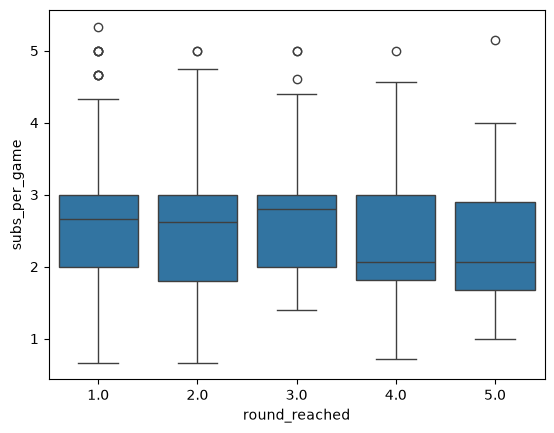

In [1631]:
''' subs per game vs stage reached'''

sns.boxplot(data=squad_exp_perform, x='round_reached', y='subs_per_game')

<Axes: xlabel='ever_won_wc', ylabel='subs_per_game'>

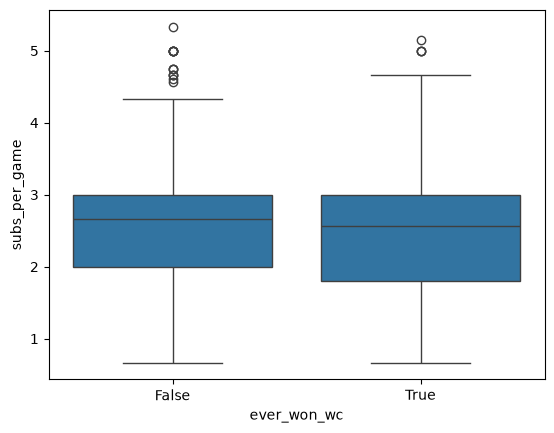

In [1632]:
''' subs per game winner vs non-winner'''

sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='subs_per_game')

(10.0, 48.998083504449006)

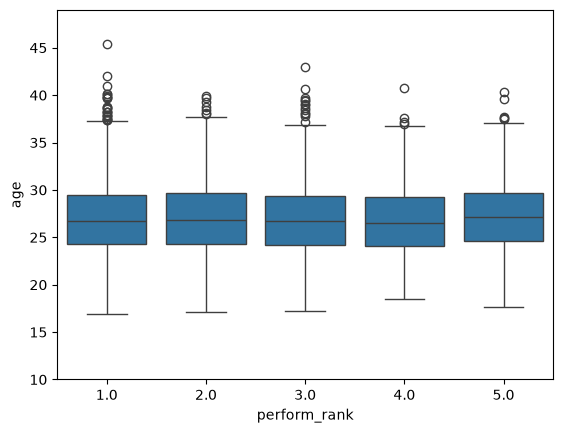

In [1633]:
''' Squad age vs success '''

# avg_age_per_sq = squad_exp_perform.groupby(['team_name','tournament_id']).agg(avg_age=('avg_age', 'mean'),\
#                                                                                max_perform=('max_performance_alltime', 'mean'),\
#                                                                                   avg_perform=('avg_performance_alltime', 'mean')).sort_values(by='max_perform', ascending=False).reset_index()
# print(avg_age_per_sq)

# plt.scatter(squad_exp_perform['avg_age'], squad_exp_perform['round_reached'])
# plt.title('Avg Squad Age vs Avg WC Stage Reached')
# plt.ylabel('WC Stage', rotation=0, labelpad=35)
# plt.xlabel('Squad Age')

# sns.boxplot(data=squad_exp_perform, x=squad_exp_perform['round_reached'], y=squad_exp_perform['avg_age'])
# sns.violinplot(data=mens_squads, x=mens_squads["perform_rank"], y=mens_squads["age"])
sns.boxplot(data=mens_squads, x=mens_squads["perform_rank"], y=mens_squads["age"])
plt.ylim(bottom=10)

<Axes: xlabel='perform_rank', ylabel='age'>

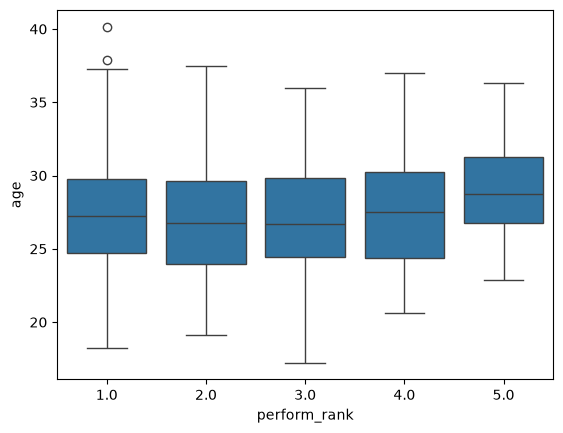

In [1634]:
as_of_year = mens_squads[mens_squads["tournament_id"] == "WC-2006"]
sns.boxplot(data=as_of_year, x=as_of_year['perform_rank'], y=as_of_year['age'])
# sns.violinplot(data=mens_squads, x=mens_squads["perform_rank"], y=mens_squads["age"])
# plt.ylim(bottom=20, top=32)

<Axes: xlabel='round_reached', ylabel='norm_n_games'>

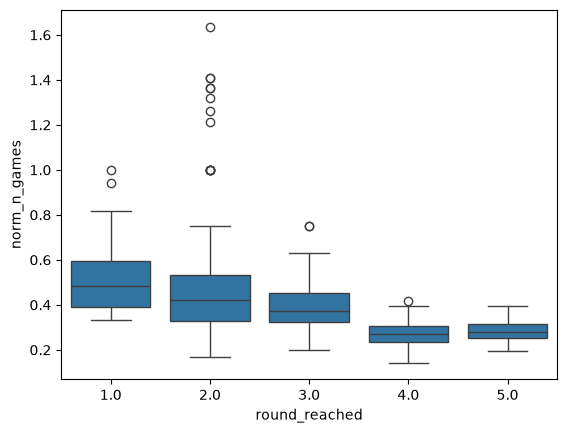

In [1635]:
stage_order = ['Group Stage', 'Round of 16', 'Quarter Final', 'Semi Final', 'Final']
squad_exp_perform["norm_n_games"] = squad_exp_perform["avg_games_played"] / squad_exp_perform["team_total_matches"]
sns.boxplot(data=squad_exp_perform, x='round_reached', y='norm_n_games')
# #order=stage_order
# plt.xlabel('Max Tournament Stage Reached')
# plt.xticks(rotation=45)
# plt.ylabel('Average\nSquad\nExperience',rotation=0, labelpad=35)
# plt.title('Squad Experience by Tournament Finish')
# plt.tight_layout()
# squad_exp_perform.head()
# filt = squad_exp_perform[["avg_games_played", "team_total_matches", "tournament_id", "team_name"]]
# filt[filt["avg_games_played"] > filt["team_total_matches"]]

In [1636]:
squad_exp_perform.head()

C:\Users\bevamin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\displayhook.py:292: UserWarning: Output cache limit (currently 1000 entries) hit.
Flushing oldest 200 entries.
  warn('Output cache limit (currently {sz} entries) hit.\n'


,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,median_performance_alltime,max_performance_alltime,ever_won_wc,avg_age,median_age,max_age,norm_n_games
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,3.0,5.0,True,25.005165,24.748802,31.334702,0.218182
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,2.0,4.0,False,25.501369,24.049281,38.173854,0.687500
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,1.0,1.0,False,25.167522,24.079398,32.301164,0.500000
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,3.0,5.0,True,24.857632,25.438741,30.253251,0.541667
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,1.0,4.0,False,26.553694,26.685832,33.437372,0.333333


Text(0.5, 0, '')

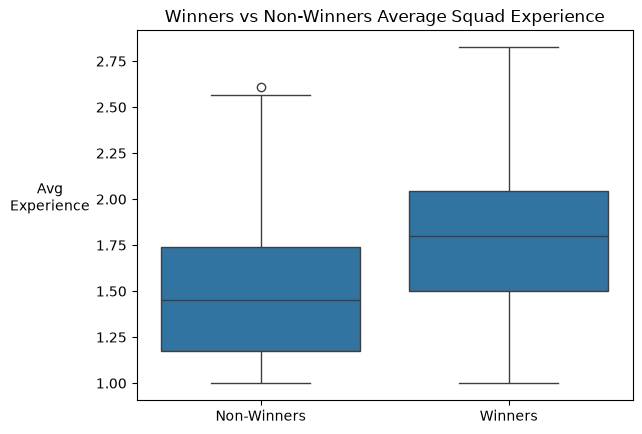

In [1637]:
""" winners vs non winners in average games played """

winners_vs_exp = squad_exp_perform[['ever_won_wc', 'avg_games_played']]
sns.boxplot(data=winners_vs_exp, x='ever_won_wc', y='avg_games_played')
plt.xticks([0, 1], ['Non-Winners', 'Winners'])
plt.title('Winners vs Non-Winners Average Squad Experience')
plt.ylabel('Avg\nExperience', rotation=0, labelpad=33)
plt.xlabel(None)

In [1638]:
position_mix = (mens_squads.groupby(['team_name', 'tournament_id', 'position_name']).size().unstack(fill_value=0).reset_index())
position_mix.sample(10)

position_name,team_name,tournament_id,defender,forward,goal keeper,midfielder
294,Northern Ireland,WC-1982,6,7,3,6
116,Croatia,WC-2002,8,6,3,6
206,Hungary,WC-1966,6,8,3,5
287,Nigeria,WC-2002,8,4,3,8
349,Saudi Arabia,WC-2018,7,3,3,10
171,France,WC-1982,7,6,3,6
190,Ghana,WC-2006,8,5,3,7
152,England,WC-1966,7,5,3,7
409,Sweden,WC-1958,5,7,3,7
448,United States,WC-2002,8,5,3,7


In [1639]:
squad_exp_perform = pd.merge(squad_exp_perform , position_mix, on=['team_name', 'tournament_id'], how='inner')

In [1640]:
squad_exp_perform

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,...,max_performance_alltime,ever_won_wc,avg_age,median_age,max_age,norm_n_games,defender,forward,goal keeper,midfielder
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,...,5.0,True,25.005165,24.748802,31.334702,0.218182,5,10,2,5
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,...,4.0,False,25.501369,24.049281,38.173854,0.687500,3,6,2,5
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,...,1.0,False,25.167522,24.079398,32.301164,0.500000,3,6,2,6
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,...,5.0,True,24.857632,25.438741,30.253251,0.541667,5,11,2,6
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,...,4.0,False,26.553694,26.685832,33.437372,0.333333,4,8,2,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,WC-2022,Switzerland,4,1.692308,1.0,4,2.0,38.0,4.750000,1.919414,...,3.0,False,27.535197,26.969199,33.924709,0.423077,8,4,4,10
485,WC-2022,Tunisia,3,1.384615,1.0,2,1.0,24.0,4.000000,1.000000,...,1.0,False,28.537145,28.821355,38.182067,0.461538,8,7,4,7
486,WC-2022,United States,4,1.038462,1.0,2,2.0,38.0,4.750000,1.873418,...,4.0,False,25.585847,24.769336,35.126626,0.259615,9,8,3,6
487,WC-2022,Uruguay,3,1.961538,1.5,4,1.0,28.0,4.666667,2.517007,...,5.0,True,28.309167,26.520192,36.758385,0.653846,9,6,3,8


In [1641]:
''' Position proportions instead of counts - teams have diff squad sizes! '''

position_cols = ['goal keeper', 'defender', 'midfielder', 'forward']

squad_exp_perform['squad_size'] = squad_exp_perform[position_cols].sum(axis=1)

for col in position_cols:
    squad_exp_perform[f'{col}_pct'] = (
        squad_exp_perform[col] / squad_exp_perform['squad_size']
    ) * 100

In [1642]:
squad_exp_perform.columns

Index(['tournament_id', 'team_name', 'team_total_matches', 'avg_games_played',
       'median_games_played', 'max_games_played', 'round_reached',
       'subs_count', 'subs_per_game', 'avg_performance_alltime',
       'median_performance_alltime', 'max_performance_alltime', 'ever_won_wc',
       'avg_age', 'median_age', 'max_age', 'norm_n_games', 'defender',
       'forward', 'goal keeper', 'midfielder', 'squad_size', 'goal keeper_pct',
       'defender_pct', 'midfielder_pct', 'forward_pct'],
      dtype='str')

Text(0.5, 1.0, 'No of Squad Defenders vs Furthest WC Stage Reached')

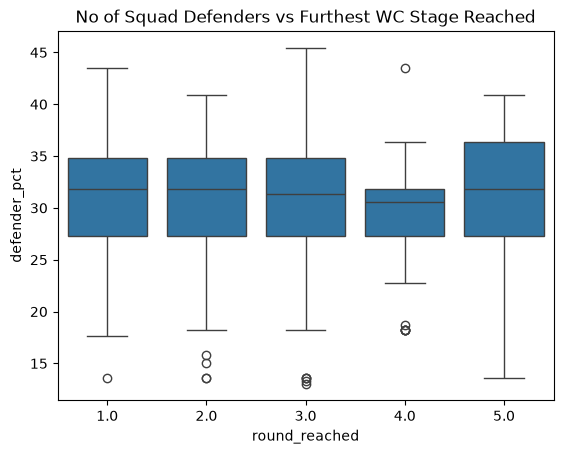

In [1643]:
''' Position mix vs tournament progression 
= no differences for other position %s other than defender below'''

sns.boxplot(data=squad_exp_perform, x='round_reached', y='defender_pct')
plt.title('No of Squad Defenders vs Furthest WC Stage Reached')

Text(0, 0.5, '%\nMidfielders')

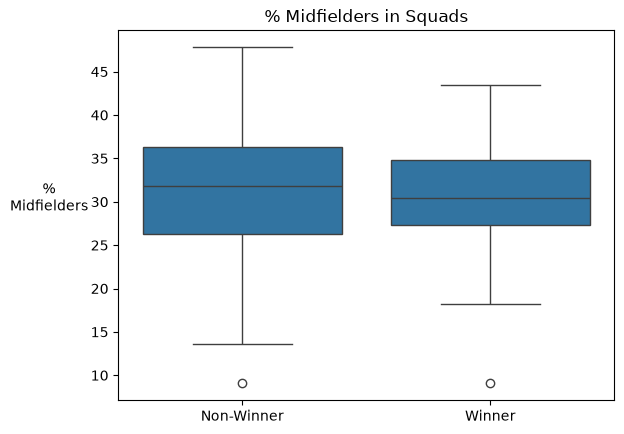

In [1644]:
''' Position makeup of winners vs non-winners '''

sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='midfielder_pct')
plt.title('% Midfielders in Squads')
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)
plt.ylabel("%\nMidfielders", rotation=0, labelpad=30)


Text(0, 0.5, '%\nForwards')

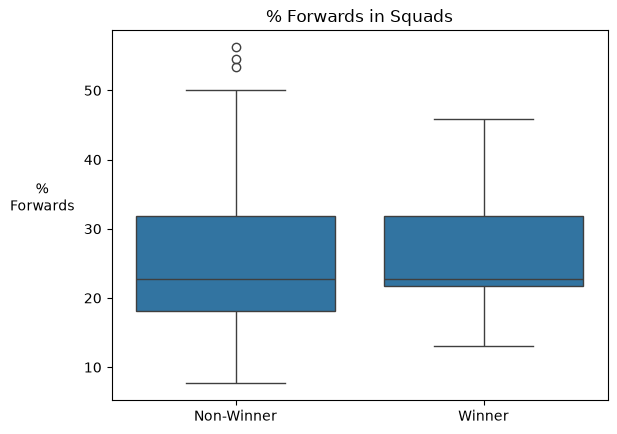

In [1645]:
sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='forward_pct')
plt.title("% Forwards in Squads")
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)
plt.ylabel("%\nForwards", rotation=0, labelpad=30)

Text(0.5, 0, 'World Cup Year')

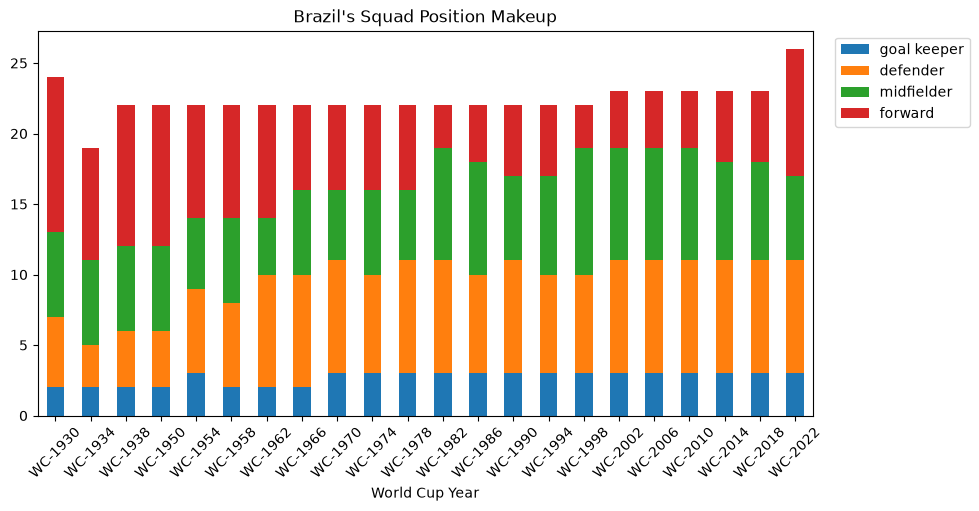

In [1646]:
brazil = squad_exp_perform[squad_exp_perform['team_name'] == 'Brazil']

brazil.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Brazil's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")



Text(0.5, 0, 'World Cup Year')

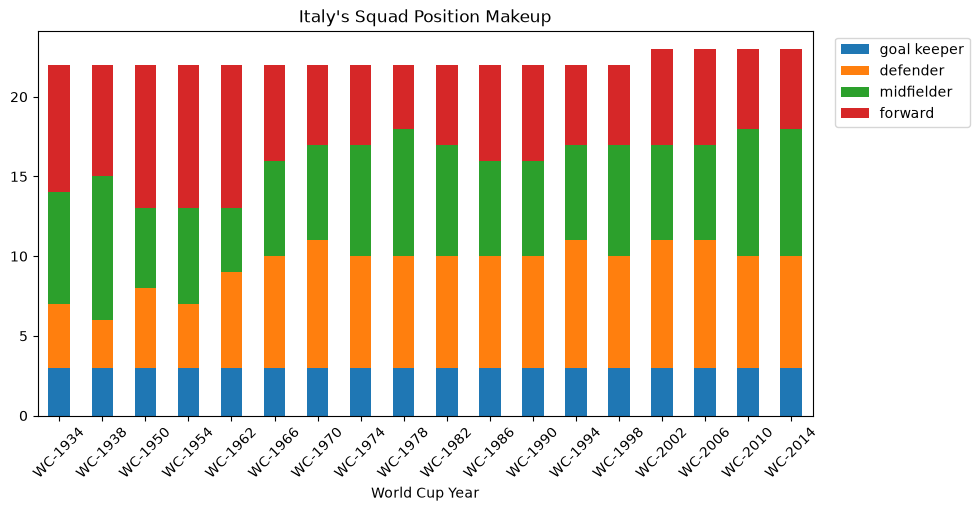

In [1647]:
italy = squad_exp_perform[squad_exp_perform['team_name'] == 'Italy']

italy.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Italy's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")

Text(0.5, 0, 'World Cup Year')

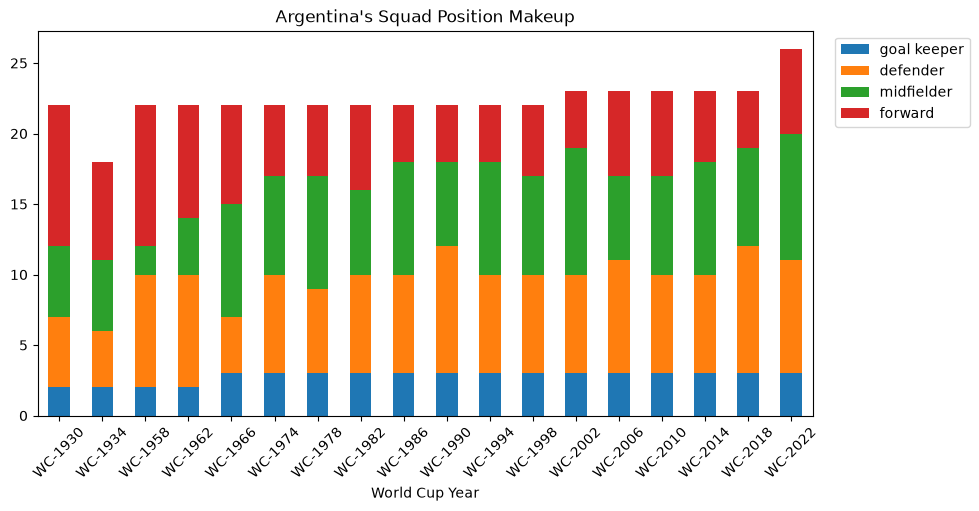

In [1648]:
argentina = squad_exp_perform[squad_exp_perform['team_name'] == 'Argentina']

argentina.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Argentina's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")

In [1649]:
mens_squads.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,...,performance,team_total_matches,start_date,subs_count,perform_rank,tournament_year,birth_date,birth_date_dt,start_date_dt,age
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,...,final,5,1930-07-13,NaN,5.0,1930,1905-05-05,1905-05-05,1930-07-13,25.188227
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,...,final,5,1930-07-13,NaN,5.0,1930,1908-10-23,1908-10-23,1930-07-13,21.719370
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,...,final,5,1930-07-13,NaN,5.0,1930,1907-02-23,1907-02-23,1930-07-13,23.383984
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,...,final,5,1930-07-13,NaN,5.0,1930,1907-02-23,1907-02-23,1930-07-13,23.383984
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,...,final,5,1930-07-13,NaN,5.0,1930,1906-03-23,1906-03-23,1930-07-13,24.306639


In [1650]:
''' Calculate returning players between tournaments'''

results = []

for team in mens_squads['team_name'].unique():
    team_df = mens_squads[mens_squads['team_name'] == team]
    tournaments = (team_df[['tournament_id', 'tournament_year']].drop_duplicates().sort_values('tournament_year'))
    tournament_list = tournaments['tournament_id'].tolist()
    for i in range(len(tournament_list) - 1):
        prev_tourn = tournament_list[i]
        next_tourn = tournament_list[i + 1]
        prev_squad = set(team_df.loc[team_df['tournament_id'] == prev_tourn,'player_id'])
        next_squad = set(team_df.loc[team_df['tournament_id'] == next_tourn,'player_id'])
        returning_players = len(prev_squad & next_squad)
        returning_pct = (returning_players / len(prev_squad)) * 100
        results.append({
            'team_name': team,
            'previous_tournament': prev_tourn,
            'next_tournament': next_tourn,
            'returning_players': returning_players,
            'previous_squad_size': len(prev_squad),
            'returning_players_pct': returning_pct
        })

stability_df = pd.DataFrame(results)

In [1651]:
stability_df

,team_name,previous_tournament,next_tournament,returning_players,previous_squad_size,returning_players_pct
0,Argentina,WC-1930,WC-1934,0,22,0.000000
1,Argentina,WC-1934,WC-1958,0,18,0.000000
2,Argentina,WC-1958,WC-1962,2,22,9.090909
3,Argentina,WC-1962,WC-1966,5,22,22.727273
4,Argentina,WC-1966,WC-1974,1,22,4.545455
...,...,...,...,...,...,...
399,Ghana,WC-2014,WC-2022,2,23,8.695652
400,Ivory Coast,WC-2006,WC-2010,11,23,47.826087
401,Ivory Coast,WC-2010,WC-2014,10,23,43.478261
402,Serbia,WC-2010,WC-2018,4,23,17.391304


In [1652]:
stability_df = stability_df.merge(squad_exp_perform[['team_name', 'tournament_id', 'round_reached', 'ever_won_wc']],
    left_on=['team_name', 'next_tournament'],
    right_on=['team_name', 'tournament_id'],
    how='left'
)

In [1653]:
stability_df

,team_name,previous_tournament,next_tournament,returning_players,previous_squad_size,returning_players_pct,tournament_id,round_reached,ever_won_wc
0,Argentina,WC-1930,WC-1934,0,22,0.000000,WC-1934,2.0,True
1,Argentina,WC-1934,WC-1958,0,18,0.000000,WC-1958,1.0,True
2,Argentina,WC-1958,WC-1962,2,22,9.090909,WC-1962,1.0,True
3,Argentina,WC-1962,WC-1966,5,22,22.727273,WC-1966,3.0,True
4,Argentina,WC-1966,WC-1974,1,22,4.545455,WC-1974,2.0,True
...,...,...,...,...,...,...,...,...,...
399,Ghana,WC-2014,WC-2022,2,23,8.695652,WC-2022,1.0,False
400,Ivory Coast,WC-2006,WC-2010,11,23,47.826087,WC-2010,1.0,False
401,Ivory Coast,WC-2010,WC-2014,10,23,43.478261,WC-2014,1.0,False
402,Serbia,WC-2010,WC-2018,4,23,17.391304,WC-2018,1.0,False


Text(0.5, 0, 'Furthest Stage Reached')

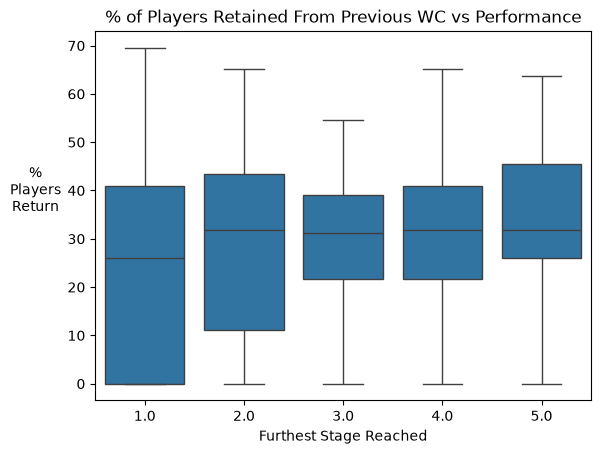

In [1654]:
sns.boxplot(data=stability_df, x='round_reached', y='returning_players_pct',)
plt.title('% of Players Retained From Previous WC vs Performance')
plt.ylabel("%\nPlayers\nReturn", rotation=0, labelpad=23)
plt.xlabel("Furthest Stage Reached")

,returning_players,previous_squad_size,returning_players_pct,round_reached
count,404.000000,404.000000,404.000000,400.000000
mean,5.910891,22.173267,26.431708,2.167500
std,4.201734,1.037595,18.648510,1.318632
min,0.000000,15.000000,0.000000,1.000000
25%,2.000000,22.000000,8.695652,1.000000
50%,6.000000,22.000000,27.272727,2.000000
75%,9.000000,23.000000,40.909091,3.000000
max,16.000000,24.000000,69.565217,5.000000


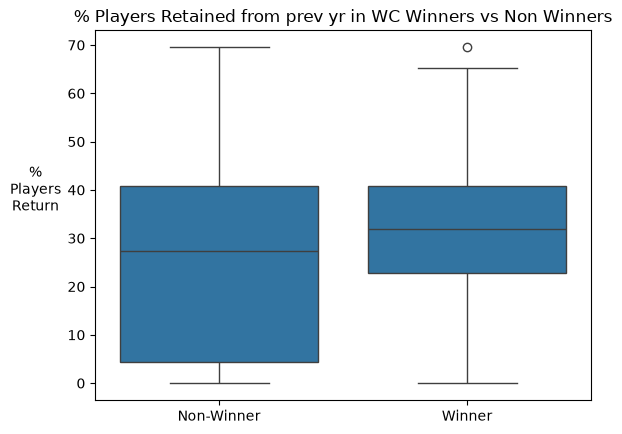

In [1655]:
sns.boxplot(data=stability_df, x='ever_won_wc', y='returning_players_pct')
plt.title('% Players Retained from prev yr in WC Winners vs Non Winners')
plt.ylabel("%\nPlayers\nReturn", rotation=0, labelpad=23)
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)

stability_df.describe()

Teams that eventually won the World Cup retained an average of X% of players from the previous tournament, compared with Y% for non-winners.

## Player Success

In [1656]:
goals.head()

,key_id,goal_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,shirt_number,player_team_id,player_team_name,player_team_code,minute_label,minute_regulation,minute_stoppage,match_period,own_goal,penalty
0,1,G-0001,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,19',19,0,first half,0,0
1,2,G-0002,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,40',40,0,first half,0,0
2,3,G-0003,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,43',43,0,first half,0,0
3,4,G-0004,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-46,...,0,T-46,Mexico,MEX,70',70,0,second half,0,0
4,5,G-0005,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,87',87,0,second half,0,0


In [1657]:
print(squad_exp_perform.columns)
print(goals.columns)
print(mens_squads.columns)


Index(['tournament_id', 'team_name', 'team_total_matches', 'avg_games_played',
       'median_games_played', 'max_games_played', 'round_reached',
       'subs_count', 'subs_per_game', 'avg_performance_alltime',
       'median_performance_alltime', 'max_performance_alltime', 'ever_won_wc',
       'avg_age', 'median_age', 'max_age', 'norm_n_games', 'defender',
       'forward', 'goal keeper', 'midfielder', 'squad_size', 'goal keeper_pct',
       'defender_pct', 'midfielder_pct', 'forward_pct'],
      dtype='str')
Index(['key_id', 'goal_id', 'tournament_id', 'tournament_name', 'match_id',
       'match_name', 'match_date', 'stage_name', 'group_name', 'team_id',
       'team_name', 'team_code', 'home_team', 'away_team', 'player_id',
       'family_name', 'given_name', 'shirt_number', 'player_team_id',
       'player_team_name', 'player_team_code', 'minute_label',
       'minute_regulation', 'minute_stoppage', 'match_period', 'own_goal',
       'penalty'],
      dtype='str')
Index(['key_id'

In [1658]:
goals_with_pos = pd.merge(goals, mens_squads[['player_id', 'tournament_id', 'position_name']], on=['player_id', 'tournament_id'], how='left')

In [1659]:
goals_with_pos

,key_id,goal_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,player_team_id,player_team_name,player_team_code,minute_label,minute_regulation,minute_stoppage,match_period,own_goal,penalty,position_name
0,1,G-0001,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,T-30,France,FRA,19',19,0,first half,0,0,forward
1,2,G-0002,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,T-30,France,FRA,40',40,0,first half,0,0,forward
2,3,G-0003,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,T-30,France,FRA,43',43,0,first half,0,0,forward
3,4,G-0004,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-46,...,T-46,Mexico,MEX,70',70,0,second half,0,0,forward
4,5,G-0005,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,T-30,France,FRA,87',87,0,second half,0,0,forward
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3632,3633,G-3633,WC-2022,2022 FIFA Men's World Cup,M-2022-64,Argentina vs France,2022-12-18,final,not applicable,T-03,...,T-03,Argentina,ARG,36',36,0,first half,0,0,forward
3633,3634,G-3634,WC-2022,2022 FIFA Men's World Cup,M-2022-64,Argentina vs France,2022-12-18,final,not applicable,T-30,...,T-30,France,FRA,80',80,0,second half,0,1,forward
3634,3635,G-3635,WC-2022,2022 FIFA Men's World Cup,M-2022-64,Argentina vs France,2022-12-18,final,not applicable,T-30,...,T-30,France,FRA,81',81,0,second half,0,0,forward
3635,3636,G-3636,WC-2022,2022 FIFA Men's World Cup,M-2022-64,Argentina vs France,2022-12-18,final,not applicable,T-03,...,T-03,Argentina,ARG,108',108,0,"extra time, second half",0,0,forward


In [1660]:
goals_by_position_pct = (goals_with_pos['position_name'].value_counts(normalize=True) * 100)
goals_by_position_pct

position_name
forward        64.264706
midfielder     25.588235
defender       10.036765
goal keeper     0.110294
Name: proportion, dtype: float64

In [1661]:
team_goals_by_position = (goals_with_pos.groupby(['tournament_id', 'team_name', 'position_name']).size().unstack(fill_value=0).reset_index())
team_goals_by_position.head(20)

position_name,tournament_id,team_name,defender,forward,goal keeper,midfielder
0,WC-1930,Argentina,0,14,0,4
1,WC-1930,Brazil,0,5,0,0
2,WC-1930,Chile,1,4,0,0
3,WC-1930,France,0,4,0,0
4,WC-1930,Mexico,2,2,0,0
5,WC-1930,Paraguay,0,1,0,0
6,WC-1930,Peru,0,1,0,0
7,WC-1930,Romania,0,3,0,0
8,WC-1930,United States,0,7,0,0
9,WC-1930,Uruguay,0,15,0,0


In [1662]:
team_goals_by_position = team_goals_by_position.merge(
    squad_exp_perform[['tournament_id', 'team_name', 'ever_won_wc']],
    on=['tournament_id', 'team_name'],
    how='left'
)


In [1663]:
team_goals_by_position.head()

,tournament_id,team_name,defender,forward,goal keeper,midfielder,ever_won_wc
0,WC-1930,Argentina,0,14,0,4,True
1,WC-1930,Brazil,0,5,0,0,True
2,WC-1930,Chile,1,4,0,0,False
3,WC-1930,France,0,4,0,0,True
4,WC-1930,Mexico,2,2,0,0,False


In [1664]:
team_goals_by_position_summary = team_goals_by_position.groupby('ever_won_wc')[['forward', 'midfielder', 'defender', 'goal keeper']].mean().reset_index()
team_goals_by_position_summary 

,ever_won_wc,forward,midfielder,defender,goal keeper
0,False,2.876133,1.268882,0.483384,0.006042
1,True,5.726619,1.985612,0.812950,0.007194


Text(0.5, 0, '')

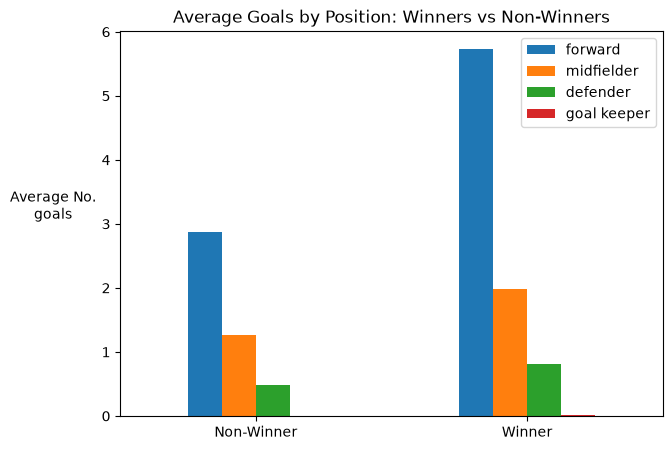

In [1665]:
team_goals_by_position_summary.plot(kind='bar',figsize=(7,5))
plt.ylabel('Average No.\ngoals', rotation=0, labelpad=35)
plt.title('Average Goals by Position: Winners vs Non-Winners')
plt.xticks(rotation=0)
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)

In [1666]:
pct_df = team_goals_by_position_summary.set_index("ever_won_wc")
pct_df = pct_df.div(pct_df.sum(axis=1), axis=0) * 100
pct_df

# ax = pct_df.plot(kind='bar', stacked=True,figsize=(8, 6))

# for container in ax.containers:
#     labels = [f'{v:.1f}%' if v > 5 else '' for v in container.datavalues]
#     ax.bar_label(container, labels=labels, label_type='center',fmt='%.1f%%')

# plt.ylabel('% of Goals', rotation=0, labelpad=20)
# plt.xlabel('Winner')
# plt.title('Distribution of Goals by Position', pad=10)
# plt.xticks([0,1], ['Non-Winner', 'Winner'], rotation=0)
# plt.xlabel(None)
# handles, labels = ax.get_legend_handles_labels()
# plt.legend(title='Position') #handles[1:-1], labels[1:-1],
# plt.show()


,forward,midfielder,defender,goal keeper
ever_won_wc,,,,
False,62.059974,27.379400,10.430248,0.130378
True,67.116358,23.271501,9.527825,0.084317


winners get more goals from forwards?


In [1667]:
''' Goal contribution diversity '''

unique_scorers = goals.groupby(['team_name', 'tournament_id']).agg(no_goals=('goal_id', 'count'), scoring_players=('player_id', list))
unique_scorers['unique_scoring_players'] = unique_scorers['scoring_players'].map(lambda x: list(set(x)))
unique_scorers['no_unique_scorers'] = unique_scorers['unique_scoring_players'].apply(len)
unique_scorers

no_goals  \
team_name  tournament_id             
Algeria    WC-1982               5   
           WC-1986               1   
           WC-2014               7   
Angola     WC-2006               1   
Argentina  WC-1930              18   
...                            ...   
Yugoslavia WC-1962              10   
           WC-1974              12   
           WC-1982               2   
           WC-1990               8   
           WC-1998               5   

                                                            scoring_players  \
team_name  tournament_id                                                      
Algeria    WC-1982            [P-45774, P-59774, P-40338, P-40338, P-68346]   
           WC-1986                                                [P-42885]   
           WC-2014        [P-12165, P-59199, P-19453, P-59147, P-24983, ...   
Angola     WC-2006                                                [P-78483]   
Argentina  WC-1930        [P-25760, P-56486, P-76546, P-56486, P-37326, ...   
...                                                                     ...   
Yugoslavia WC-1962        [P-47998, P-05537, P-55024, P-05537, P-55024, ...   
           WC-1974        [P-74389, P-88088, P-28747, P-20553, P-74389, ...   
           WC-1982                                       [P-96969, P-43672]   
           WC-1990        [P-01298, P-01298, P-74361, P-31892, P-31892, ...   
           WC-1998            [P-04188, P-82329, P-93318, P-43392, P-43392]   

                                                     unique_scoring_players  \
team_name  tournament_id                                                      
Algeria    WC-1982                     [P-40338, P-68346, P-59774, P-45774]   
           WC-1986                                                [P-42885]   
           WC-2014            [P-12165, P-59147, P-59199, P-24983, P-19453]   
Angola     WC-2006                                                [P-78483]   
Argentina  WC-1930        [P-37326, P-25760, P-70166, P-76546, P-56486, ...   
...                                                                     ...   
Yugoslavia WC-1962            [P-55024, P-47998, P-67185, P-55272, P-05537]   
           WC-1974        [P-74389, P-46434, P-80725, P-88088, P-28747, ...   
           WC-1982                                       [P-96969, P-43672]   
           WC-1990            [P-74361, P-93318, P-62861, P-31892, P-01298]   
           WC-1998                     [P-93318, P-04188, P-82329, P-43392]   

                          no_unique_scorers  
team_name  tournament_id                     
Algeria    WC-1982                        4  
           WC-1986                        1  
           WC-2014                        5  
Angola     WC-2006                        1  
Argentina  WC-1930                        7  
...                                     ...  
Yugoslavia WC-1962                        5  
           WC-1974                        8  
           WC-1982                        2  
           WC-1990                        5  
           WC-1998                        4  

[600 rows x 4 columns]

In [1668]:
unique_scorers_summary = unique_scorers.drop(['scoring_players', 'unique_scoring_players'], axis=1).reset_index()
unique_scorers_summary

,team_name,tournament_id,no_goals,no_unique_scorers
0,Algeria,WC-1982,5,4
1,Algeria,WC-1986,1,1
2,Algeria,WC-2014,7,5
3,Angola,WC-2006,1,1
4,Argentina,WC-1930,18,7
...,...,...,...,...
595,Yugoslavia,WC-1962,10,5
596,Yugoslavia,WC-1974,12,8
597,Yugoslavia,WC-1982,2,2
598,Yugoslavia,WC-1990,8,5


In [1669]:
squad_exp_perform = pd.merge(squad_exp_perform, unique_scorers_summary, on=['tournament_id', 'team_name'], how='left')

In [1670]:
squad_exp_perform['no_uniq_scorer_per_goal'] = squad_exp_perform['no_goals'] / squad_exp_perform['no_unique_scorers']

In [1671]:
# squad_exp_perform.fillna(0, inplace=True)
# squad_exp_perform[["no_goals", "no_unique_scorers" , "team_name", "no_uniq_scorer_per_goal", "tournament_id"]].head(50)
squad_exp_perform.head(20)

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,...,goal keeper,midfielder,squad_size,goal keeper_pct,defender_pct,midfielder_pct,forward_pct,no_goals,no_unique_scorers,no_uniq_scorer_per_goal
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,...,2,5,22,9.090909,22.727273,22.727273,45.454545,18.0,7.0,2.571429
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,...,2,5,16,12.500000,18.750000,31.250000,37.500000,NaN,NaN,NaN
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,...,2,6,17,11.764706,17.647059,35.294118,35.294118,NaN,NaN,NaN
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,...,2,6,24,8.333333,20.833333,25.000000,45.833333,5.0,2.0,2.500000
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,...,2,5,19,10.526316,21.052632,26.315789,42.105263,5.0,3.0,1.666667
5,WC-1930,France,3,1.562500,1.0,3,1.0,NaN,NaN,2.932394,...,2,4,16,12.500000,25.000000,25.000000,37.500000,4.0,3.0,1.333333
6,WC-1930,Mexico,3,1.000000,1.0,1,1.0,NaN,NaN,1.653439,...,2,4,17,11.764706,17.647059,23.529412,47.058824,4.0,3.0,1.333333
7,WC-1930,Paraguay,2,1.000000,1.0,1,1.0,NaN,NaN,1.631285,...,2,6,22,9.090909,18.181818,27.272727,45.454545,1.0,1.0,1.000000
8,WC-1930,Peru,2,1.000000,1.0,1,1.0,NaN,NaN,1.594595,...,2,7,22,9.090909,18.181818,31.818182,40.909091,1.0,1.0,1.000000
9,WC-1930,Romania,2,1.266667,1.0,3,1.0,NaN,NaN,1.897959,...,2,3,15,13.333333,26.666667,20.000000,40.000000,3.0,3.0,1.000000


## Team Playing Style

Text(0, 0.5, 'No.\nUnique\nScorers\nper Goal')

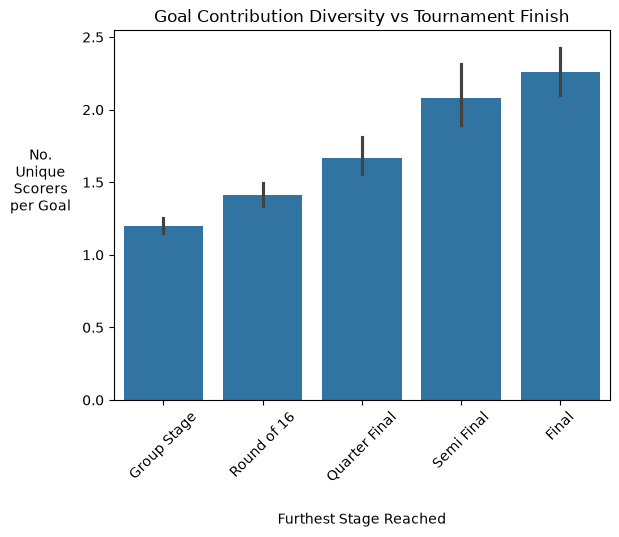

In [1672]:
sns.barplot(data=squad_exp_perform, x='round_reached', y='no_uniq_scorer_per_goal' )
plt.xticks([float(n) for n in range(5)], stage_order, rotation=45)
plt.title('Goal Contribution Diversity vs Tournament Finish')
plt.xlabel('Furthest Stage Reached', labelpad=20)
plt.ylabel('No.\nUnique\nScorers\nper Goal', rotation=0, labelpad=30)

In [1673]:
''' When do successful teams score? 
use: minute_regulation
minute_stoppage
match_period

Do champions:

score early?
score late?
perform better in knockout games?

sns.heatmap() - Rows = teams
Columns = time windows or
sns.lineplot()'''

' When do successful teams score? \nuse: minute_regulation\nminute_stoppage\nmatch_period\n\nDo champions:\n\nscore early?\nscore late?\nperform better in knockout games?\n\nsns.heatmap() - Rows = teams\nColumns = time windows or\nsns.lineplot()'

In [1674]:
goals.columns

Index(['key_id', 'goal_id', 'tournament_id', 'tournament_name', 'match_id',
       'match_name', 'match_date', 'stage_name', 'group_name', 'team_id',
       'team_name', 'team_code', 'home_team', 'away_team', 'player_id',
       'family_name', 'given_name', 'shirt_number', 'player_team_id',
       'player_team_name', 'player_team_code', 'minute_label',
       'minute_regulation', 'minute_stoppage', 'match_period', 'own_goal',
       'penalty'],
      dtype='str')

In [1675]:
tourn_winners_mens

,tournament_id,winner
0,WC-1930,Uruguay
1,WC-1934,Italy
2,WC-1938,Italy
3,WC-1950,Uruguay
4,WC-1954,West Germany
5,WC-1958,Brazil
6,WC-1962,Brazil
7,WC-1966,England
8,WC-1970,Brazil
9,WC-1974,West Germany


In [1676]:
goals['wc_winner'] = goals['team_name'].isin(tourn_winners_mens['winner'])

In [1677]:
goals['goal_minute'] = goals['minute_regulation'] + goals['minute_stoppage'].fillna(0)

In [1678]:
def make_bins_easy(bins:list) -> list:
    labels = []
    for n, idx in enumerate(bins):
        if n == 0:
            continue
        labels.append(f"{bins[n-1]}-{idx}")
    
    # labels.append(f"{bins[-1]}+")
    return labels

intervals = list(range(0,120,5))
goals['minute_bin'] = pd.cut(goals['goal_minute'],
    bins=intervals,
    labels=make_bins_easy(intervals),
    include_lowest=True
)

In [1679]:
goals.sample(5)

,key_id,goal_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,player_team_code,minute_label,minute_regulation,minute_stoppage,match_period,own_goal,penalty,wc_winner,goal_minute,minute_bin
517,518,G-0518,WC-1958,1958 FIFA Men's World Cup,M-1958-20,France vs Scotland,1958-06-15,group stage,Group 2,T-30,...,FRA,22',22,0,first half,0,0,True,22,20-25
2311,2312,G-2312,WC-2003,2003 FIFA Women's World Cup,M-2003-22,North Korea vs United States,2003-09-28,group stage,Group A,T-83,...,USA,17',17,0,first half,0,1,False,17,15-20
2617,2618,G-2618,WC-2010,2010 FIFA Men's World Cup,M-2010-10,Japan vs Cameroon,2010-06-14,group stage,Group E,T-44,...,JPN,39',39,0,first half,0,0,False,39,35-40
3597,3598,G-3598,WC-2022,2022 FIFA Men's World Cup,M-2022-52,England vs Senegal,2022-12-04,round of 16,not applicable,T-28,...,ENG,45'+3',45,3,"first half, stoppage time",0,0,True,48,45-50
1127,1128,G-1128,WC-1982,1982 FIFA Men's World Cup,M-1982-27,Soviet Union vs Scotland,1982-06-22,group stage,Group 6,T-64,...,SCO,15',15,0,first half,0,0,False,15,10-15


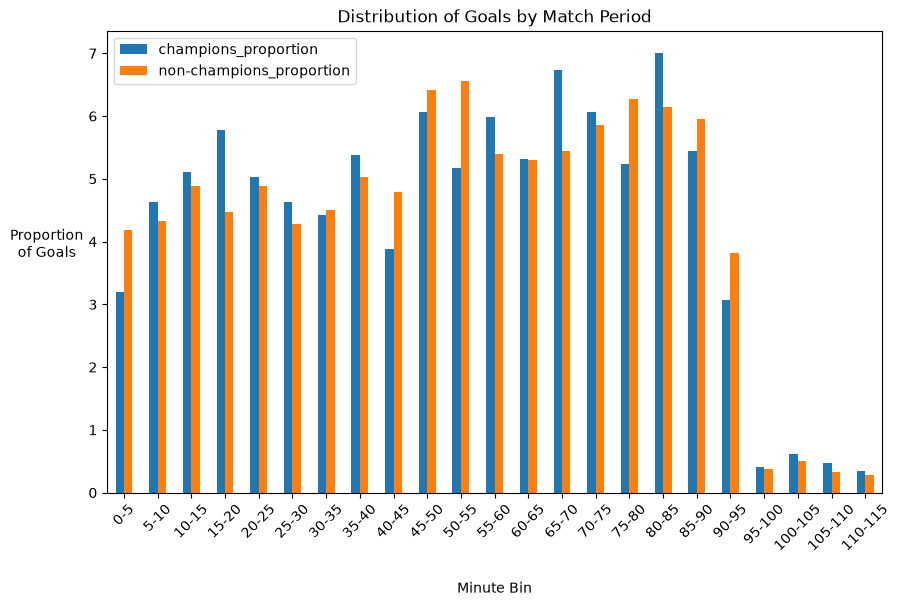

In [1680]:
champion_goals = goals[goals['wc_winner']]

champ_dist = (
    champion_goals['minute_bin']
    .value_counts(normalize=True)
    .sort_index().reset_index().rename(columns={'proportion': 'champions_proportion'})
)

nonchamp_dist = (
    goals[~goals['wc_winner']]
    ['minute_bin']
    .value_counts(normalize=True)
    .sort_index().reset_index().rename(columns={'proportion': 'non-champions_proportion'})
)

concat_dist = pd.merge(champ_dist, nonchamp_dist, on='minute_bin', how='inner')
concat_dist[["non-champions_proportion", "champions_proportion"]] = concat_dist[["non-champions_proportion", "champions_proportion"]] * 100

concat_dist.set_index('minute_bin').plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title('Distribution of Goals by Match Period')
plt.xlabel('Minute Bin', labelpad=20)
plt.ylabel('Proportion\nof Goals', rotation=0, labelpad=30)
plt.xticks(rotation=45)
plt.show()

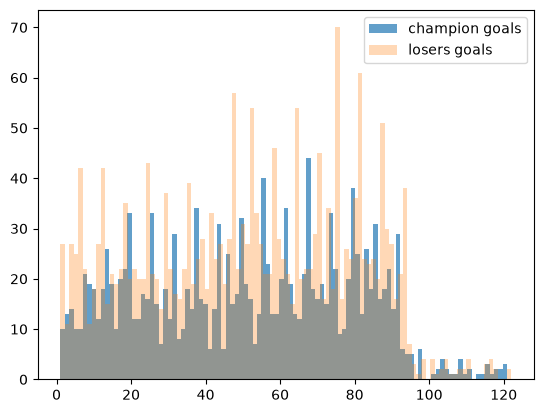

In [1681]:

champion_goals = goals[goals['wc_winner']]
champion_goals.head()
non_champ_goals = goals[~goals["wc_winner"]]
non_champ_goals.head()

plt.hist(champion_goals["goal_minute"], bins=100, alpha=0.7, label="champion goals")
plt.hist(non_champ_goals["goal_minute"], bins=100, alpha=0.3, label="losers goals")
plt.legend()

In [1682]:
'''managers - from same countries as the team theyre managing?
'''
print(managers.info())
managers.head()

<class 'pandas.DataFrame'>
RangeIndex: 637 entries, 0 to 636
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   key_id           637 non-null    int64
 1   tournament_id    637 non-null    str  
 2   tournament_name  637 non-null    str  
 3   team_id          637 non-null    str  
 4   team_name        637 non-null    str  
 5   team_code        637 non-null    str  
 6   manager_id       637 non-null    str  
 7   family_name      637 non-null    str  
 8   given_name       637 non-null    str  
 9   country_name     637 non-null    str  
dtypes: int64(1), str(9)
memory usage: 49.9 KB
None


,key_id,tournament_id,tournament_name,team_id,team_name,team_code,manager_id,family_name,given_name,country_name
0,1,WC-1930,1930 FIFA Men's World Cup,T-56,Peru,PER,M-061,Bru,Francisco,Spain
1,2,WC-1930,1930 FIFA Men's World Cup,T-30,France,FRA,M-075,Caudron,Raoul,France
2,3,WC-1930,1930 FIFA Men's World Cup,T-09,Brazil,BRA,M-091,de Carvalho Rodrigues,Píndaro,Brazil
3,4,WC-1930,1930 FIFA Men's World Cup,T-55,Paraguay,PRY,M-109,Durand Laguna,José,Argentina
4,5,WC-1930,1930 FIFA Men's World Cup,T-06,Belgium,BEL,M-140,Goetinck,Hector,Belgium


In [1683]:
managers['mger_from_team_country'] = managers.apply(lambda row: True if row['team_name'] == row['country_name'] else False, axis=1)

In [1684]:
managers.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,manager_id,family_name,given_name,country_name,mger_from_team_country
0,1,WC-1930,1930 FIFA Men's World Cup,T-56,Peru,PER,M-061,Bru,Francisco,Spain,False
1,2,WC-1930,1930 FIFA Men's World Cup,T-30,France,FRA,M-075,Caudron,Raoul,France,True
2,3,WC-1930,1930 FIFA Men's World Cup,T-09,Brazil,BRA,M-091,de Carvalho Rodrigues,Píndaro,Brazil,True
3,4,WC-1930,1930 FIFA Men's World Cup,T-55,Paraguay,PRY,M-109,Durand Laguna,José,Argentina,False
4,5,WC-1930,1930 FIFA Men's World Cup,T-06,Belgium,BEL,M-140,Goetinck,Hector,Belgium,True


In [1685]:
tourn_winners_mens['winner']

0          Uruguay
1            Italy
2            Italy
3          Uruguay
4     West Germany
5           Brazil
6           Brazil
7          England
8           Brazil
9     West Germany
10       Argentina
11           Italy
12       Argentina
13    West Germany
15          Brazil
17          France
19          Brazil
21           Italy
23           Spain
25         Germany
27          France
29       Argentina
Name: winner, dtype: str

In [1686]:
''' percent/number of teams where manager is from teams country '''

manager_from_team_country = managers.groupby('team_name').agg(from_team_country_sum=('mger_from_team_country', 'sum'), total=('mger_from_team_country', 'size')).reset_index()
manager_from_team_country['pct_from_team_country'] = round((manager_from_team_country['from_team_country_sum'] / manager_from_team_country['total']) * 100)
manager_from_team_country['wc_winner'] = manager_from_team_country.apply(lambda row: True if row['team_name'] in (tourn_winners_mens['winner'].to_list()) else False, axis=1)
manager_from_team_country

,team_name,from_team_country_sum,total,pct_from_team_country,wc_winner
0,Algeria,4,5,80.0,False
1,Angola,1,1,100.0,False
2,Argentina,21,22,95.0,True
3,Australia,6,13,46.0,False
4,Austria,8,8,100.0,False
...,...,...,...,...,...
83,Uruguay,14,14,100.0,True
84,Wales,2,2,100.0,False
85,West Germany,0,10,0.0,True
86,Yugoslavia,10,10,100.0,False


In [1687]:
filt = manager_from_team_country[manager_from_team_country['pct_from_team_country'] < 0]
filt

,team_name,from_team_country_sum,total,pct_from_team_country,wc_winner


Text(0.5, 1.0, "% of managers from team's country")

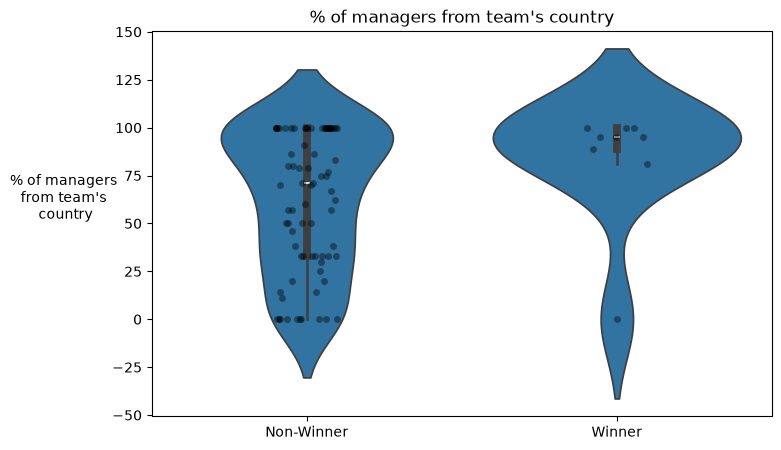

In [1688]:
''' managers from teams country vs success'''

plt.figure(figsize=(8,5))

sns.violinplot(
    data=manager_from_team_country,
    x='wc_winner',
    y='pct_from_team_country',
    inner='box'
)

sns.stripplot(
    data=manager_from_team_country,
    x='wc_winner',
    y='pct_from_team_country',
    color='black',
    alpha=0.4
)

# sns.boxplot(data=manager_from_team_country,
# x='wc_winner',
# y='pct_from_team_country')

plt.ylabel("% of managers\nfrom team's\n country", rotation=0, labelpad=35)
plt.xticks([0,1], ['Non-Winner', 'Winner'], rotation=0)
plt.xlabel(None)
plt.title("% of managers from team's country")


<Axes: xlabel='wc_winner', ylabel='pct_from_team_country'>

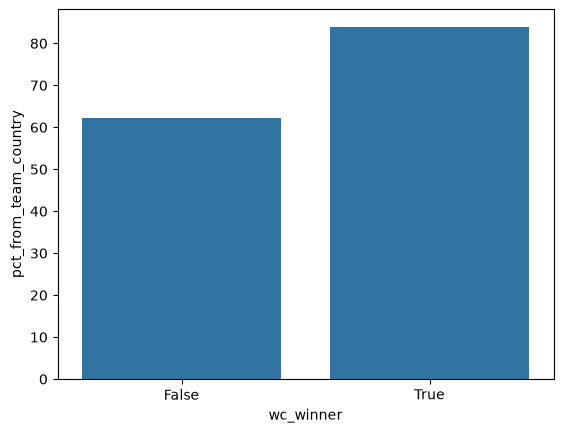

In [1689]:
winner_summary = (
    manager_from_team_country
    .groupby('wc_winner')['pct_from_team_country']
    .mean()
    .reset_index()
)

sns.barplot(
    data=winner_summary,
    x='wc_winner',
    y='pct_from_team_country'
)

In [1693]:
''' host countries '''

hosts['performance'].unique()

<StringArray>
[         'champions',      'quater-finals',         'runners-up',
      'quarter-final',        'third place', 'second group stage',
     'quarter-finals',        'round of 16',       'fourth place',
        'group stage']
Length: 10, dtype: str

In [1698]:
hosts.loc[(hosts['performance'] == 'quarter-final') | (hosts['performance'] == 'quater-finals'), 'performance'] = 'quarter-finals'
mens_hosts = hosts[~hosts['tournament_name'].str.contains('Women')]

In [1700]:
mens_hosts.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,performance
0,1,WC-1930,1930 FIFA Men's World Cup,T-84,Uruguay,URY,champions
1,2,WC-1934,1934 FIFA Men's World Cup,T-41,Italy,ITA,champions
2,3,WC-1938,1938 FIFA Men's World Cup,T-30,France,FRA,quarter-finals
3,4,WC-1950,1950 FIFA Men's World Cup,T-09,Brazil,BRA,runners-up
4,5,WC-1954,1954 FIFA Men's World Cup,T-75,Switzerland,CHE,quarter-finals


In [1755]:
stages = {'group stage': 1, 'second group stage': 2, 'round of 16' : 2, \
           'quarter-finals': 3, 'fourth place': 4, 'third place': 4, 'runners-up': 5, 'champions': 5}
stages_order = stages.keys()
stages_order

stage_names = ["group stage", "round of 16", "quarter finals", "semi finals", "finals"]

# performance_rank = {
#     'group stage': 1,
#     'round of 16': 2,
#     'second group stage': 2,
#     'quarter-finals': 3,
#     'quarter-final': 3,
#     'semi-finals': 4,
#     'third-place match': 4,
#     'final': 5
# }

In [1753]:
mens_hosts['perform_map'] = mens_hosts['performance'].map(stages)
mens_hosts.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,performance,perform_map
0,1,WC-1930,1930 FIFA Men's World Cup,T-84,Uruguay,URY,champions,5
1,2,WC-1934,1934 FIFA Men's World Cup,T-41,Italy,ITA,champions,5
2,3,WC-1938,1938 FIFA Men's World Cup,T-30,France,FRA,quarter-finals,3
3,4,WC-1950,1950 FIFA Men's World Cup,T-09,Brazil,BRA,runners-up,5
4,5,WC-1954,1954 FIFA Men's World Cup,T-75,Switzerland,CHE,quarter-finals,3


In [ ]:
mens_hosts_agg = mens_hosts.groupby('perform_map')['perform_map'].count().reset_index(name='count')
mens_hosts_agg["stage"] = stage_names


In [1768]:
sum_of_finishes_hosts = mens_hosts_agg["count"].sum()
mens_hosts_agg["proportion"] = (mens_hosts_agg["count"] / sum_of_finishes_hosts)*100
mens_hosts_agg.head()


,perform_map,count,stage,proportion
0,1,2,group stage,8.695652
1,2,3,round of 16,13.043478
2,3,5,quarter finals,21.739130
3,4,5,semi finals,21.739130
4,5,8,finals,34.782609


In [1751]:
mens_hosts_agg.sort_values(by='perform_map', ascending=False)

,performance,count,perform_map
0,champions,6,5
5,runners-up,2,5
7,third place,3,4
1,fourth place,2,4
3,quarter-finals,5,3
4,round of 16,2,2
6,second group stage,1,2
2,group stage,2,1


england only won when they hosted / italy won b2b because of corruption - mussolini

In [1736]:
squad_exp_perform.head()

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,...,goal keeper,midfielder,squad_size,goal keeper_pct,defender_pct,midfielder_pct,forward_pct,no_goals,no_unique_scorers,no_uniq_scorer_per_goal
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,...,2,5,22,9.090909,22.727273,22.727273,45.454545,18.0,7.0,2.571429
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,...,2,5,16,12.500000,18.750000,31.250000,37.500000,NaN,NaN,NaN
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,...,2,6,17,11.764706,17.647059,35.294118,35.294118,NaN,NaN,NaN
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,...,2,6,24,8.333333,20.833333,25.000000,45.833333,5.0,2.0,2.500000
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,...,2,5,19,10.526316,21.052632,26.315789,42.105263,5.0,3.0,1.666667


In [1737]:
#squad_exp_perform['hosted?'] = squad_exp_perform.apply(lambda row: True if row['team_name'] in )


squad_exp_perform = pd.merge(squad_exp_perform, mens_hosts.rename(columns={'team_name': 'host_name'}), on='tournament_id', how='left')

In [ ]:
squad_exp_perform.drop('performance', axis=1, inplace=True)


In [1746]:
squad_exp_perform_nonhosts = squad_exp_perform[squad_exp_perform['host_name']!= squad_exp_perform['team_name']]
squad_exp_perform_nonhosts.head()

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,...,midfielder_pct,forward_pct,no_goals,no_unique_scorers,no_uniq_scorer_per_goal,key_id,tournament_name,team_id,host_name,team_code
0,WC-1930,Argentina,5,1.090909,1.0,2,5.0,NaN,NaN,3.082294,...,22.727273,45.454545,18.0,7.0,2.571429,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,...,31.250000,37.500000,NaN,NaN,NaN,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,...,35.294118,35.294118,NaN,NaN,NaN,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,...,25.000000,45.833333,5.0,2.0,2.500000,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,...,26.315789,42.105263,5.0,3.0,1.666667,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY


In [1761]:
squad_exp_perform_nonhosts = squad_exp_perform_nonhosts.groupby('round_reached')["round_reached"].count().reset_index(name="count")

In [1765]:
squad_exp_perform_nonhosts["stage"] = stage_names
sum_of_finishes = squad_exp_perform_nonhosts["count"].sum()
squad_exp_perform_nonhosts["proportion"] = (squad_exp_perform_nonhosts["count"] / sum_of_finishes)*100
squad_exp_perform_nonhosts.head()


,round_reached,count,stage,proportion
0,1.0,236,group stage,47.676768
1,2.0,116,round of 16,23.434343
2,3.0,67,quarter finals,13.535354
3,4.0,39,semi finals,7.878788
4,5.0,37,finals,7.474747


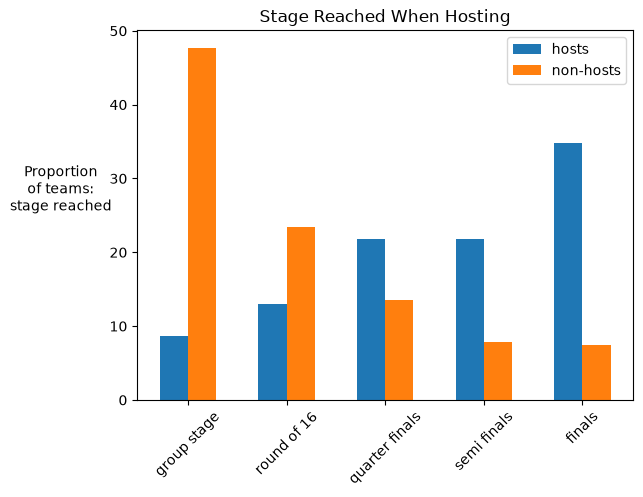

In [1777]:
# sns.barplot(data=mens_hosts_agg, x='stage', y='proportion') # order=stages_order
# sns.barplot(data=squad_exp_perform_nonhosts, x="stage", y="proportion", alpha=0.3)
plt.grouped_bar([mens_hosts_agg["proportion"], squad_exp_perform_nonhosts["proportion"]], tick_labels=stage_names, labels=["hosts", "non-hosts"])
plt.xticks(rotation=45)
plt.title('Stage Reached When Hosting')
plt.ylabel('Proportion\nof teams:\nstage reached', rotation=0, labelpad=35)
plt.legend()

In [ ]:
'''penality dependence?? - calculate penalty % per team per tourn'''

penalties.head()

,key_id,penalty_kick_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,team_name,team_code,home_team,away_team,player_id,family_name,given_name,shirt_number,converted
0,1,PK-001,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-68969,Kaltz,Manfred,20,1
1,2,PK-002,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-48686,Breitner,Paul,3,1
2,3,PK-003,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-45695,Stielike,Uli,15,0
3,4,PK-004,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-89975,Littbarski,Pierre,7,1
4,5,PK-005,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-59574,Rummenigge,Karl-Heinz,11,1


In [1779]:
mens_pens = penalties[~penalties['tournament_name'].str.contains('Women')]
mens_pens.head()

,key_id,penalty_kick_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,team_name,team_code,home_team,away_team,player_id,family_name,given_name,shirt_number,converted
0,1,PK-001,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-68969,Kaltz,Manfred,20,1
1,2,PK-002,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-48686,Breitner,Paul,3,1
2,3,PK-003,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-45695,Stielike,Uli,15,0
3,4,PK-004,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-89975,Littbarski,Pierre,7,1
4,5,PK-005,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-59574,Rummenigge,Karl-Heinz,11,1


In [1796]:
squad_exp_perform[squad_exp_perform['round_reached'] == 1.0]

,tournament_id,team_name,team_total_matches,avg_games_played,median_games_played,max_games_played,round_reached,subs_count,subs_per_game,avg_performance_alltime,...,midfielder_pct,forward_pct,no_goals,no_unique_scorers,no_uniq_scorer_per_goal,key_id,tournament_name,team_id,host_name,team_code
1,WC-1930,Belgium,2,1.375000,1.0,3,1.0,NaN,NaN,2.016181,...,31.250000,37.500000,NaN,NaN,NaN,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
2,WC-1930,Bolivia,2,1.000000,1.0,1,1.0,NaN,NaN,1.000000,...,35.294118,35.294118,NaN,NaN,NaN,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
3,WC-1930,Brazil,2,1.083333,1.0,2,1.0,NaN,NaN,3.425532,...,25.000000,45.833333,5.0,2.0,2.500000,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
4,WC-1930,Chile,3,1.000000,1.0,1,1.0,NaN,NaN,1.680203,...,26.315789,42.105263,5.0,3.0,1.666667,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
5,WC-1930,France,3,1.562500,1.0,3,1.0,NaN,NaN,2.932394,...,25.000000,37.500000,4.0,3.0,1.333333,1,1930 FIFA Men's World Cup,T-84,Uruguay,URY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
511,WC-2022,Saudi Arabia,3,1.346154,1.0,2,1.0,28.0,4.666667,1.158273,...,34.615385,23.076923,3.0,2.0,1.500000,31,2022 FIFA Men's World Cup,T-59,Qatar,QAT
513,WC-2022,Serbia,3,1.461538,1.0,2,1.0,30.0,5.000000,1.000000,...,38.461538,23.076923,5.0,4.0,1.250000,31,2022 FIFA Men's World Cup,T-59,Qatar,QAT
517,WC-2022,Tunisia,3,1.384615,1.0,2,1.0,24.0,4.000000,1.000000,...,26.923077,26.923077,1.0,1.0,1.000000,31,2022 FIFA Men's World Cup,T-59,Qatar,QAT
519,WC-2022,Uruguay,3,1.961538,1.5,4,1.0,28.0,4.666667,2.517007,...,30.769231,23.076923,2.0,1.0,2.000000,31,2022 FIFA Men's World Cup,T-59,Qatar,QAT


In [ ]:
mens_pens_agg = mens_pens.groupby(['tournament_id', 'team_name']).\
    agg(sum_converted_pens=('converted', 'sum'), total_pens=('converted', 'count')).reset_index()

mens_pens_agg['pct_converted'] = round((mens_pens_agg['sum_converted_pens'] / mens_pens_agg['total_pens']) * 100)
mens_pens_agg = pd.merge(mens_pens_agg, squad_exp_perform[['tournament_id', 'team_name','round_reached']], how='left', on=['tournament_id', 'team_name'])

In [1803]:
# mens_pens[mens_pens["stage_name"].str.contains("semi")]
mens_pens["stage_name"].unique()

<StringArray>
['semi-finals', 'quarter-finals', 'round of 16', 'final']
Length: 4, dtype: str

In [1795]:
mens_pens_agg[mens_pens_agg['round_reached'] == 1.0]

,tournament_id,team_name,sum_converted_pens,total_pens,pct_converted,round_reached


<Axes: xlabel='round_reached', ylabel='pct_converted'>

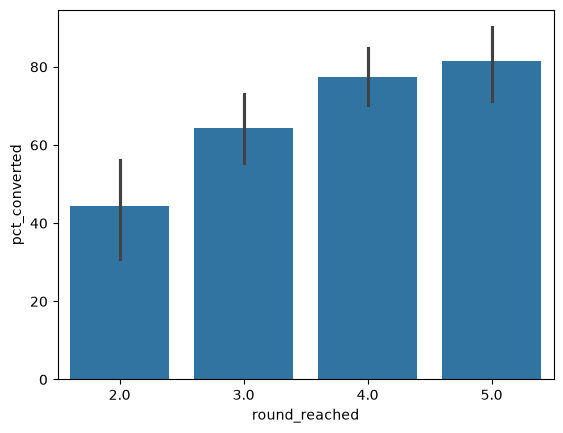

In [1791]:
sns.barplot(data=mens_pens_agg, x='round_reached', y='pct_converted')

In [1691]:
'''13. Build a "champion profile"
Calculate averages for:

average age
average experience
squad size
defenders %
midfielders %
forwards %
unique scorers
goals scored
penalty %
late goals %

Compare:

Champions
vs
Non-champions

RADAR CHART'''

'13. Build a "champion profile"\nCalculate averages for:\n\naverage age\naverage experience\nsquad size\ndefenders %\nmidfielders %\nforwards %\nunique scorers\ngoals scored\npenalty %\nlate goals %\n\nCompare:\n\nChampions\nvs\nNon-champions\n\nRADAR CHART'

Winning nations had managers from their own country in x% of tournaments, compared with x% for non-winning nations.

## 10. Machine Learning Analysis
- Which variables were most useful in predicting World Cup success?

## 11. Conclusions